In [36]:
# ============================================================
# NEW CELL 1 — LOAD SPANISH OPERATIONAL DATA
# ============================================================

import pandas as pd
import numpy as np

operational_path = (
    r"C:\Users\mt_ha\Desktop\TFM\olive_oil"
    r"\operational_monthly_2016_2026.csv"
)

operational = pd.read_csv(operational_path)

operational["date"] = pd.to_datetime(
    operational["date"]
)

operational = (
    operational
    .sort_values("date")
    .reset_index(drop=True)
)

print("Shape:", operational.shape)

print("\nDate range:")
print(
    operational["date"].min(),
    "to",
    operational["date"].max()
)

print("\nColumns:")
print(operational.columns.tolist())

print("\nMissing values:")
print(operational.isna().sum())

print("\nFirst rows:")
print(operational.head())

print("\nLast rows:")
print(operational.tail())

Shape: (118, 8)

Date range:
2016-10-01 00:00:00 to 2026-07-01 00:00:00

Columns:
['date', 'marketing_year', 'initial_stock_kt', 'production_kt', 'imports_kt', 'domestic_market_kt', 'exports_kt', 'final_stock_kt']

Missing values:
date                   0
marketing_year         0
initial_stock_kt       0
production_kt         38
imports_kt             0
domestic_market_kt     0
exports_kt             4
final_stock_kt         0
dtype: int64

First rows:
        date marketing_year  initial_stock_kt  production_kt  imports_kt  \
0 2016-10-01        2016/17             331.0            9.7         8.9   
1 2016-11-01        2016/17             244.1           93.5         9.7   
2 2016-12-01        2016/17             228.3          456.2        15.6   
3 2017-01-01        2016/17             578.9          526.2         4.6   
4 2017-02-01        2016/17             969.5          155.3         6.3   

   domestic_market_kt  exports_kt  final_stock_kt  
0                35.4        70.1 

In [37]:
# ============================================================
# NEW CELL 2 — AUDIT MISSING OPERATIONAL VALUES
# ============================================================

print("Months with missing production:")
print(
    operational.loc[
        operational["production_kt"].isna(),
        ["date", "marketing_year", "production_kt"]
    ].to_string(index=False)
)

print("\nMonths with missing exports:")
print(
    operational.loc[
        operational["exports_kt"].isna(),
        [
            "date",
            "marketing_year",
            "initial_stock_kt",
            "production_kt",
            "imports_kt",
            "domestic_market_kt",
            "exports_kt",
            "final_stock_kt"
        ]
    ].to_string(index=False)
)

print("\nSeptember observations 2017–2020:")
print(
    operational.loc[
        operational["date"].isin(pd.to_datetime([
            "2017-09-01",
            "2018-09-01",
            "2019-09-01",
            "2020-09-01"
        ])),
        [
            "date",
            "initial_stock_kt",
            "production_kt",
            "imports_kt",
            "domestic_market_kt",
            "exports_kt",
            "final_stock_kt"
        ]
    ].to_string(index=False)
)

Months with missing production:
      date marketing_year  production_kt
2017-06-01        2016/17            NaN
2017-07-01        2016/17            NaN
2017-08-01        2016/17            NaN
2017-09-01        2016/17            NaN
2018-06-01        2017/18            NaN
2018-07-01        2017/18            NaN
2018-08-01        2017/18            NaN
2018-09-01        2017/18            NaN
2019-06-01        2018/19            NaN
2019-07-01        2018/19            NaN
2019-08-01        2018/19            NaN
2019-09-01        2018/19            NaN
2020-06-01        2019/20            NaN
2020-07-01        2019/20            NaN
2020-08-01        2019/20            NaN
2020-09-01        2019/20            NaN
2021-06-01        2020/21            NaN
2021-07-01        2020/21            NaN
2021-08-01        2020/21            NaN
2021-09-01        2020/21            NaN
2022-06-01        2021/22            NaN
2022-07-01        2021/22            NaN
2022-08-01        2021/22

In [38]:
# ============================================================
# NEW CELL 3 — CREATE CORRECTED OPERATIONAL MODELLING DATA
# ============================================================

operational_model = operational.copy()

# ------------------------------------------------------------
# 1. Non-production months represented as zero production
# ------------------------------------------------------------
operational_model["production_kt"] = (
    operational_model["production_kt"].fillna(0)
)

# ------------------------------------------------------------
# 2. Correct verified September 2017–2020 observations
# ------------------------------------------------------------
september_corrections = {
    "2017-09-01": {"domestic_market_kt": 31.2, "exports_kt": 70.0},
    "2018-09-01": {"domestic_market_kt": 34.0, "exports_kt": 88.0},
    "2019-09-01": {"domestic_market_kt": 39.2, "exports_kt": 99.0},
    "2020-09-01": {"domestic_market_kt": 44.6, "exports_kt": 102.0},
}

for date, values in september_corrections.items():
    mask = operational_model["date"] == pd.Timestamp(date)

    operational_model.loc[
        mask, "domestic_market_kt"
    ] = values["domestic_market_kt"]

    operational_model.loc[
        mask, "exports_kt"
    ] = values["exports_kt"]

# ------------------------------------------------------------
# 3. Calculate stock implied by monthly flows
# ------------------------------------------------------------
operational_model["calculated_final_stock_kt"] = (
    operational_model["initial_stock_kt"]
    + operational_model["production_kt"]
    + operational_model["imports_kt"]
    - operational_model["domestic_market_kt"]
    - operational_model["exports_kt"]
)

operational_model["balance_error_kt"] = (
    operational_model["final_stock_kt"]
    - operational_model["calculated_final_stock_kt"]
)

# ------------------------------------------------------------
# 4. Validation output
# ------------------------------------------------------------
print("Remaining missing values:")
print(operational_model.isna().sum())

print("\nSeptember corrections:")
print(
    operational_model.loc[
        operational_model["date"].isin(
            pd.to_datetime(list(september_corrections.keys()))
        ),
        [
            "date",
            "initial_stock_kt",
            "production_kt",
            "imports_kt",
            "domestic_market_kt",
            "exports_kt",
            "final_stock_kt",
            "calculated_final_stock_kt",
            "balance_error_kt"
        ]
    ].to_string(index=False)
)

print("\nStock-flow balance error summary:")
print(
    operational_model["balance_error_kt"]
    .abs()
    .describe()
)

print("\nLargest absolute balance errors:")
print(
    operational_model.loc[
        operational_model["balance_error_kt"].abs()
        .sort_values(ascending=False)
        .head(10)
        .index,
        [
            "date",
            "final_stock_kt",
            "calculated_final_stock_kt",
            "balance_error_kt"
        ]
    ].sort_values(
        "balance_error_kt",
        key=abs,
        ascending=False
    ).to_string(index=False)
)

Remaining missing values:
date                         0
marketing_year               0
initial_stock_kt             0
production_kt                0
imports_kt                   0
domestic_market_kt           0
exports_kt                   0
final_stock_kt               0
calculated_final_stock_kt    0
balance_error_kt             0
dtype: int64

September corrections:
      date  initial_stock_kt  production_kt  imports_kt  domestic_market_kt  exports_kt  final_stock_kt  calculated_final_stock_kt  balance_error_kt
2017-09-01             399.6            0.0         6.0                31.2        70.0           304.4                      304.4     -5.684342e-14
2018-09-01             485.8            0.0        11.0                34.0        88.0           374.8                      374.8      0.000000e+00
2019-09-01             885.0            0.0         8.5                39.2        99.0           755.3                      755.3      0.000000e+00
2020-09-01             616.1   

In [39]:
# ============================================================
# NEW CELL 4 — CREATE FUTURE STOCK TARGETS
# ============================================================

stock_df = operational_model.copy()

# ------------------------------------------------------------
# 1. Forecast targets
# ------------------------------------------------------------
stock_df["target_stock_t1"] = (
    stock_df["final_stock_kt"].shift(-1)
)

stock_df["target_stock_t3"] = (
    stock_df["final_stock_kt"].shift(-3)
)

# ------------------------------------------------------------
# 2. Corresponding target dates
# ------------------------------------------------------------
stock_df["target_date_t1"] = (
    stock_df["date"].shift(-1)
)

stock_df["target_date_t3"] = (
    stock_df["date"].shift(-3)
)

# ------------------------------------------------------------
# 3. Display selected observations
# ------------------------------------------------------------
print(
    stock_df[
        [
            "date",
            "final_stock_kt",
            "target_date_t1",
            "target_stock_t1",
            "target_date_t3",
            "target_stock_t3"
        ]
    ].head(8).to_string(index=False)
)

print("\nLast observations:")
print(
    stock_df[
        [
            "date",
            "final_stock_kt",
            "target_date_t1",
            "target_stock_t1",
            "target_date_t3",
            "target_stock_t3"
        ]
    ].tail(6).to_string(index=False)
)

print("\nAvailable targets:")
print(
    "t+1:",
    stock_df["target_stock_t1"].notna().sum()
)

print(
    "t+3:",
    stock_df["target_stock_t3"].notna().sum()
)

      date  final_stock_kt target_date_t1  target_stock_t1 target_date_t3  target_stock_t3
2016-10-01           244.1     2016-11-01            228.3     2017-01-01            969.5
2016-11-01           228.3     2016-12-01            578.9     2017-02-01            995.0
2016-12-01           578.9     2017-01-01            969.5     2017-03-01            894.7
2017-01-01           969.5     2017-02-01            995.0     2017-04-01            805.4
2017-02-01           995.0     2017-03-01            894.7     2017-05-01            689.9
2017-03-01           894.7     2017-04-01            805.4     2017-06-01            591.9
2017-04-01           805.4     2017-05-01            689.9     2017-07-01            491.8
2017-05-01           689.9     2017-06-01            591.9     2017-08-01            399.6

Last observations:
      date  final_stock_kt target_date_t1  target_stock_t1 target_date_t3  target_stock_t3
2026-02-01       985.59432     2026-03-01        952.05616     2026-05

In [40]:
# ============================================================
# NEW CELL 5 — CREATE STOCK FORECASTING FEATURES
# ============================================================

stock_features = stock_df.copy()

# ------------------------------------------------------------
# 1. Calendar / seasonal information
# ------------------------------------------------------------
stock_features["month"] = stock_features["date"].dt.month

# ------------------------------------------------------------
# 2. Stock history
# ------------------------------------------------------------
for lag in [1, 2, 3, 6, 12]:
    stock_features[f"stock_lag_{lag}"] = (
        stock_features["final_stock_kt"].shift(lag)
    )

# ------------------------------------------------------------
# 3. Operational history
# ------------------------------------------------------------
operational_vars = [
    "production_kt",
    "imports_kt",
    "exports_kt",
    "domestic_market_kt"
]

for variable in operational_vars:
    for lag in [1, 2, 3]:
        stock_features[f"{variable}_lag_{lag}"] = (
            stock_features[variable].shift(lag)
        )

# ------------------------------------------------------------
# 4. Define feature groups
# ------------------------------------------------------------

# Simple inventory-history model
stock_history_features = [
    "final_stock_kt",
    "stock_lag_1",
    "stock_lag_2",
    "stock_lag_3",
    "stock_lag_6",
    "stock_lag_12",
    "month"
]

# Spanish operational model
spanish_operational_features = (
    stock_history_features
    + [
        "production_kt",
        "imports_kt",
        "exports_kt",
        "domestic_market_kt"
    ]
    + [
        f"{variable}_lag_{lag}"
        for variable in operational_vars
        for lag in [1, 2, 3]
    ]
)

# ------------------------------------------------------------
# 5. Inspect resulting structure
# ------------------------------------------------------------
print("Stock-history features:")
print(stock_history_features)

print("\nNumber of stock-history features:")
print(len(stock_history_features))

print("\nNumber of Spanish operational features:")
print(len(spanish_operational_features))

print("\nSpanish operational features:")
print(spanish_operational_features)

print("\nMissing values caused by lag construction:")
print(
    stock_features[
        spanish_operational_features
    ].isna().sum()
)

print("\nDataset shape:")
print(stock_features.shape)

Stock-history features:
['final_stock_kt', 'stock_lag_1', 'stock_lag_2', 'stock_lag_3', 'stock_lag_6', 'stock_lag_12', 'month']

Number of stock-history features:
7

Number of Spanish operational features:
23

Spanish operational features:
['final_stock_kt', 'stock_lag_1', 'stock_lag_2', 'stock_lag_3', 'stock_lag_6', 'stock_lag_12', 'month', 'production_kt', 'imports_kt', 'exports_kt', 'domestic_market_kt', 'production_kt_lag_1', 'production_kt_lag_2', 'production_kt_lag_3', 'imports_kt_lag_1', 'imports_kt_lag_2', 'imports_kt_lag_3', 'exports_kt_lag_1', 'exports_kt_lag_2', 'exports_kt_lag_3', 'domestic_market_kt_lag_1', 'domestic_market_kt_lag_2', 'domestic_market_kt_lag_3']

Missing values caused by lag construction:
final_stock_kt               0
stock_lag_1                  1
stock_lag_2                  2
stock_lag_3                  3
stock_lag_6                  6
stock_lag_12                12
month                        0
production_kt                0
imports_kt              

In [41]:
# ============================================================
# NEW CELL 6 — PREPARE LEAKAGE-SAFE FORECASTING DATASETS
# ============================================================

# ------------------------------------------------------------
# 1. Keep observations with complete predictor information
# ------------------------------------------------------------

required_features = spanish_operational_features

stock_t1 = (
    stock_features
    .dropna(
        subset=required_features
        + ["target_stock_t1", "target_date_t1"]
    )
    .copy()
    .reset_index(drop=True)
)

stock_t3 = (
    stock_features
    .dropna(
        subset=required_features
        + ["target_stock_t3", "target_date_t3"]
    )
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Basic validation
# ------------------------------------------------------------

print("T+1 dataset")
print("------------")
print("Observations:", len(stock_t1))
print(
    "Predictor dates:",
    stock_t1["date"].min(),
    "to",
    stock_t1["date"].max()
)
print(
    "Target dates:",
    stock_t1["target_date_t1"].min(),
    "to",
    stock_t1["target_date_t1"].max()
)

print("\nT+3 dataset")
print("------------")
print("Observations:", len(stock_t3))
print(
    "Predictor dates:",
    stock_t3["date"].min(),
    "to",
    stock_t3["date"].max()
)
print(
    "Target dates:",
    stock_t3["target_date_t3"].min(),
    "to",
    stock_t3["target_date_t3"].max()
)

# ------------------------------------------------------------
# 3. Verify target alignment
# ------------------------------------------------------------

print("\nFirst 5 T+1 observations:")
print(
    stock_t1[
        [
            "date",
            "final_stock_kt",
            "target_date_t1",
            "target_stock_t1"
        ]
    ].head().to_string(index=False)
)

print("\nFirst 5 T+3 observations:")
print(
    stock_t3[
        [
            "date",
            "final_stock_kt",
            "target_date_t3",
            "target_stock_t3"
        ]
    ].head().to_string(index=False)
)

# ------------------------------------------------------------
# 4. Demonstrate leakage-safe training rule
# ------------------------------------------------------------

example_origin = stock_t3.iloc[60]["date"]

eligible_training = stock_t3[
    stock_t3["target_date_t3"] <= example_origin
]

print("\nExample T+3 forecast origin:")
print(example_origin)

print("Number of eligible training observations:")
print(len(eligible_training))

print("Latest target date allowed in training:")
print(eligible_training["target_date_t3"].max())

print("Target being forecast from this origin:")
print(
    stock_t3.loc[
        stock_t3["date"] == example_origin,
        "target_date_t3"
    ].iloc[0]
)

T+1 dataset
------------
Observations: 105
Predictor dates: 2017-10-01 00:00:00 to 2026-06-01 00:00:00
Target dates: 2017-11-01 00:00:00 to 2026-07-01 00:00:00

T+3 dataset
------------
Observations: 103
Predictor dates: 2017-10-01 00:00:00 to 2026-04-01 00:00:00
Target dates: 2018-01-01 00:00:00 to 2026-07-01 00:00:00

First 5 T+1 observations:
      date  final_stock_kt target_date_t1  target_stock_t1
2017-10-01           231.7     2017-11-01            334.0
2017-11-01           334.0     2017-12-01            677.2
2017-12-01           677.2     2018-01-01            983.7
2018-01-01           983.7     2018-02-01           1062.2
2018-02-01          1062.2     2018-03-01            996.6

First 5 T+3 observations:
      date  final_stock_kt target_date_t3  target_stock_t3
2017-10-01           231.7     2018-01-01            983.7
2017-11-01           334.0     2018-02-01           1062.2
2017-12-01           677.2     2018-03-01            996.6
2018-01-01           983.7     2018

In [42]:
# ============================================================
# NEW CELL 7 — ROLLING NAIVE STOCK BENCHMARKS
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd


def forecast_metrics(y_true, y_pred):
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    mape = np.mean(
        np.abs((y_true - y_pred) / y_true)
    ) * 100
    
    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }


def evaluate_stock_benchmarks(
    df,
    target_col,
    target_date_col,
    n_test=44
):
    
    test_df = df.tail(n_test).copy()
    
    results = []
    predictions = []
    
    for _, row in test_df.iterrows():
        
        origin_date = row["date"]
        target_date = row[target_date_col]
        actual = row[target_col]
        
        # -----------------------------------------
        # Benchmark 1: persistence
        # -----------------------------------------
        persistence_pred = row["final_stock_kt"]
        
        # -----------------------------------------
        # Benchmark 2: seasonal naive
        # Stock corresponding to target month - 12m
        # -----------------------------------------
        seasonal_reference_date = (
            target_date - pd.DateOffset(months=12)
        )
        
        seasonal_match = operational_model.loc[
            operational_model["date"] == seasonal_reference_date,
            "final_stock_kt"
        ]
        
        seasonal_pred = (
            seasonal_match.iloc[0]
            if len(seasonal_match) > 0
            else np.nan
        )
        
        predictions.append({
            "origin_date": origin_date,
            "target_date": target_date,
            "actual": actual,
            "persistence": persistence_pred,
            "seasonal_naive": seasonal_pred
        })
    
    predictions = pd.DataFrame(predictions)
    
    for model in ["persistence", "seasonal_naive"]:
        
        valid = predictions[
            predictions[model].notna()
        ]
        
        metrics = forecast_metrics(
            valid["actual"],
            valid[model]
        )
        
        results.append({
            "Model": model,
            "N": len(valid),
            **metrics
        })
    
    return pd.DataFrame(results), predictions


# ------------------------------------------------------------
# T+1
# ------------------------------------------------------------

results_t1, benchmark_predictions_t1 = (
    evaluate_stock_benchmarks(
        stock_t1,
        "target_stock_t1",
        "target_date_t1"
    )
)

# ------------------------------------------------------------
# T+3
# ------------------------------------------------------------

results_t3, benchmark_predictions_t3 = (
    evaluate_stock_benchmarks(
        stock_t3,
        "target_stock_t3",
        "target_date_t3"
    )
)

print("T+1 STOCK FORECAST BENCHMARKS")
print(results_t1.to_string(index=False))

print("\nT+3 STOCK FORECAST BENCHMARKS")
print(results_t3.to_string(index=False))

print("\nT+1 evaluation period:")
print(
    benchmark_predictions_t1["target_date"].min(),
    "to",
    benchmark_predictions_t1["target_date"].max()
)

print("\nT+3 evaluation period:")
print(
    benchmark_predictions_t3["target_date"].min(),
    "to",
    benchmark_predictions_t3["target_date"].max()
)

T+1 STOCK FORECAST BENCHMARKS
         Model  N        MAE       RMSE      MAPE
   persistence 44 113.322297 143.495003 21.785503
seasonal_naive 44 179.803998 245.103452 33.481779

T+3 STOCK FORECAST BENCHMARKS
         Model  N        MAE       RMSE      MAPE
   persistence 44 290.694961 350.547467 54.804985
seasonal_naive 44 179.803998 245.103452 33.481779

T+1 evaluation period:
2022-12-01 00:00:00 to 2026-07-01 00:00:00

T+3 evaluation period:
2022-12-01 00:00:00 to 2026-07-01 00:00:00


In [43]:
# ============================================================
# NEW CELL 8 — LEAKAGE-SAFE ROLLING RIDGE FORECASTS
# Stock history vs Spanish operational information
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


def rolling_ridge_forecast(
    df,
    features,
    target_col,
    target_date_col,
    n_test=44,
    alpha=10
):
    
    test_df = df.tail(n_test).copy()
    predictions = []
    
    for _, test_row in test_df.iterrows():
        
        origin_date = test_row["date"]
        
        # ----------------------------------------------------
        # CRITICAL LEAKAGE RULE:
        # use only observations whose target was already
        # observable at the forecast origin
        # ----------------------------------------------------
        train_df = df[
            df[target_date_col] <= origin_date
        ].copy()
        
        X_train = train_df[features]
        y_train = train_df[target_col]
        
        X_test = test_row[features].to_frame().T
        
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha))
        ])
        
        model.fit(X_train, y_train)
        
        prediction = model.predict(X_test)[0]
        
        predictions.append({
            "origin_date": origin_date,
            "target_date": test_row[target_date_col],
            "actual": test_row[target_col],
            "predicted": prediction,
            "n_train": len(train_df)
        })
    
    predictions = pd.DataFrame(predictions)
    
    metrics = forecast_metrics(
        predictions["actual"],
        predictions["predicted"]
    )
    
    return predictions, metrics


# ============================================================
# T+1
# ============================================================

ridge_hist_t1_pred, ridge_hist_t1 = rolling_ridge_forecast(
    stock_t1,
    stock_history_features,
    "target_stock_t1",
    "target_date_t1"
)

ridge_ops_t1_pred, ridge_ops_t1 = rolling_ridge_forecast(
    stock_t1,
    spanish_operational_features,
    "target_stock_t1",
    "target_date_t1"
)


# ============================================================
# T+3
# ============================================================

ridge_hist_t3_pred, ridge_hist_t3 = rolling_ridge_forecast(
    stock_t3,
    stock_history_features,
    "target_stock_t3",
    "target_date_t3"
)

ridge_ops_t3_pred, ridge_ops_t3 = rolling_ridge_forecast(
    stock_t3,
    spanish_operational_features,
    "target_stock_t3",
    "target_date_t3"
)


# ============================================================
# RESULTS TABLE
# ============================================================

ridge_results = pd.DataFrame([
    {
        "Horizon": "t+1",
        "Model": "Ridge - stock history",
        **ridge_hist_t1
    },
    {
        "Horizon": "t+1",
        "Model": "Ridge - Spanish operations",
        **ridge_ops_t1
    },
    {
        "Horizon": "t+3",
        "Model": "Ridge - stock history",
        **ridge_hist_t3
    },
    {
        "Horizon": "t+3",
        "Model": "Ridge - Spanish operations",
        **ridge_ops_t3
    }
])

print(ridge_results.to_string(index=False))


# ============================================================
# INCREMENTAL OPERATIONAL VALUE
# Positive = improvement
# ============================================================

improvement_t1 = (
    (ridge_hist_t1["MAE"] - ridge_ops_t1["MAE"])
    / ridge_hist_t1["MAE"]
    * 100
)

improvement_t3 = (
    (ridge_hist_t3["MAE"] - ridge_ops_t3["MAE"])
    / ridge_hist_t3["MAE"]
    * 100
)

print("\nOperational information — MAE improvement")
print(f"T+1: {improvement_t1:.2f}%")
print(f"T+3: {improvement_t3:.2f}%")

print("\nTraining sizes:")
print(
    "T+1:",
    ridge_ops_t1_pred["n_train"].min(),
    "to",
    ridge_ops_t1_pred["n_train"].max()
)

print(
    "T+3:",
    ridge_ops_t3_pred["n_train"].min(),
    "to",
    ridge_ops_t3_pred["n_train"].max()
)

Horizon                      Model        MAE       RMSE      MAPE
    t+1      Ridge - stock history  95.754424 120.816068 25.270366
    t+1 Ridge - Spanish operations  60.649883  78.572919 15.008027
    t+3      Ridge - stock history 247.000147 285.541788 65.524088
    t+3 Ridge - Spanish operations 172.545302 216.328747 44.500661

Operational information — MAE improvement
T+1: 36.66%
T+3: 30.14%

Training sizes:
T+1: 61 to 104
T+3: 57 to 100


In [44]:
# ============================================================
# NEW CELL 9B — LEAKAGE-SAFE ROLLING XGBOOST
# Corrected numeric dtypes
# ============================================================

from xgboost import XGBRegressor


def rolling_xgb_forecast(
    df,
    features,
    target_col,
    target_date_col,
    n_test=44
):
    
    test_df = df.tail(n_test).copy()
    predictions = []
    
    for _, test_row in test_df.iterrows():
        
        origin_date = test_row["date"]
        
        # ----------------------------------------------------
        # Leakage-safe training set
        # ----------------------------------------------------
        train_df = df[
            df[target_date_col] <= origin_date
        ].copy()
        
        # ----------------------------------------------------
        # Explicit numeric conversion for XGBoost
        # ----------------------------------------------------
        X_train = (
            train_df[features]
            .apply(pd.to_numeric, errors="raise")
            .astype(float)
        )
        
        y_train = (
            pd.to_numeric(
                train_df[target_col],
                errors="raise"
            )
            .astype(float)
        )
        
        X_test = (
            pd.DataFrame(
                [test_row[features].to_dict()]
            )[features]
            .apply(pd.to_numeric, errors="raise")
            .astype(float)
        )
        
        # ----------------------------------------------------
        # Conservative fixed XGBoost specification
        # ----------------------------------------------------
        model = XGBRegressor(
            n_estimators=150,
            max_depth=2,
            learning_rate=0.03,
            min_child_weight=4,
            subsample=0.8,
            colsample_bytree=0.7,
            reg_alpha=0.5,
            reg_lambda=5,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=1
        )
        
        model.fit(X_train, y_train)
        
        prediction = model.predict(X_test)[0]
        
        predictions.append({
            "origin_date": origin_date,
            "target_date": test_row[target_date_col],
            "actual": float(test_row[target_col]),
            "predicted": float(prediction),
            "n_train": len(train_df)
        })
    
    predictions = pd.DataFrame(predictions)
    
    metrics = forecast_metrics(
        predictions["actual"],
        predictions["predicted"]
    )
    
    return predictions, metrics


# ============================================================
# T+1
# ============================================================

xgb_hist_t1_pred, xgb_hist_t1 = rolling_xgb_forecast(
    stock_t1,
    stock_history_features,
    "target_stock_t1",
    "target_date_t1"
)

xgb_ops_t1_pred, xgb_ops_t1 = rolling_xgb_forecast(
    stock_t1,
    spanish_operational_features,
    "target_stock_t1",
    "target_date_t1"
)


# ============================================================
# T+3
# ============================================================

xgb_hist_t3_pred, xgb_hist_t3 = rolling_xgb_forecast(
    stock_t3,
    stock_history_features,
    "target_stock_t3",
    "target_date_t3"
)

xgb_ops_t3_pred, xgb_ops_t3 = rolling_xgb_forecast(
    stock_t3,
    spanish_operational_features,
    "target_stock_t3",
    "target_date_t3"
)


# ============================================================
# RESULTS TABLE
# ============================================================

xgb_results = pd.DataFrame([
    {
        "Horizon": "t+1",
        "Model": "XGBoost - stock history",
        **xgb_hist_t1
    },
    {
        "Horizon": "t+1",
        "Model": "XGBoost - Spanish operations",
        **xgb_ops_t1
    },
    {
        "Horizon": "t+3",
        "Model": "XGBoost - stock history",
        **xgb_hist_t3
    },
    {
        "Horizon": "t+3",
        "Model": "XGBoost - Spanish operations",
        **xgb_ops_t3
    }
])

print(xgb_results.to_string(index=False))


# ============================================================
# INCREMENTAL VALUE
# ============================================================

xgb_improvement_t1 = (
    (xgb_hist_t1["MAE"] - xgb_ops_t1["MAE"])
    / xgb_hist_t1["MAE"]
    * 100
)

xgb_improvement_t3 = (
    (xgb_hist_t3["MAE"] - xgb_ops_t3["MAE"])
    / xgb_hist_t3["MAE"]
    * 100
)

print("\nOperational information — MAE improvement")
print(f"T+1: {xgb_improvement_t1:.2f}%")
print(f"T+3: {xgb_improvement_t3:.2f}%")

Horizon                        Model        MAE       RMSE      MAPE
    t+1      XGBoost - stock history  88.404271 113.994511 24.304793
    t+1 XGBoost - Spanish operations  86.082907 105.614091 20.692877
    t+3      XGBoost - stock history 210.916323 255.266200 51.871939
    t+3 XGBoost - Spanish operations 190.173525 220.432335 42.093543

Operational information — MAE improvement
T+1: 2.63%
T+3: 9.83%


In [46]:
# ============================================================
# NEW CELL 10 — LOAD AND INSPECT INTERNATIONAL TRADE DATA
# ============================================================

# Replace ONLY this path with your existing trade file
trade_path = r"C:\Users\mt_ha\Desktop\TFM\olive_oil\YOUR_TRADE_FILE.csv"

trade = pd.read_csv(trade_path)

print("Shape:")
print(trade.shape)

print("\nColumns:")
print(trade.columns.tolist())

print("\nFirst rows:")
print(trade.head())

print("\nData types:")
print(trade.dtypes)

print("\nMissing values:")
print(trade.isna().sum())

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\mt_ha\\Desktop\\TFM\\olive_oil\\YOUR_TRADE_FILE.csv'

In [47]:
# ============================================================
# CELL 10A — FIND EXISTING DATA FILES
# ============================================================

from pathlib import Path

folder = Path(r"C:\Users\mt_ha\Desktop\TFM\olive_oil")

files = []

for extension in ["*.csv", "*.xlsx", "*.xls"]:
    files.extend(folder.rglob(extension))

print("Files found:\n")

for i, file in enumerate(files, start=1):
    print(f"{i}. {file}")

Files found:

1. C:\Users\mt_ha\Desktop\TFM\olive_oil\operational_monthly_2016_2026.csv
2. C:\Users\mt_ha\Desktop\TFM\olive_oil\price_clean.csv
3. C:\Users\mt_ha\Desktop\TFM\olive_oil\diccionary.xlsx
4. C:\Users\mt_ha\Desktop\TFM\olive_oil\operational_monthly_2016_2026.xlsx
5. C:\Users\mt_ha\Desktop\TFM\olive_oil\table_one_prices_market_eu_2010_26.xlsx
6. C:\Users\mt_ha\Desktop\TFM\olive_oil\table_two_volum_export_import_value_20_26.xlsx
7. C:\Users\mt_ha\Desktop\TFM\olive_oil\New folder\excel\INFORME FINAL de la Situación de Mercado del Sector del Aceite de oliva__Campaña 202425_Excel_.xlsx
8. C:\Users\mt_ha\Desktop\TFM\olive_oil\New folder\excel\INFORME MENSUAL de la Situación de Mercado del Sector del Aceite de Oliva y la Aceituna de Mesa_Julio 2026-Excel.xlsx
9. C:\Users\mt_ha\Desktop\TFM\olive_oil\New folder\excel\informecierrecampanadelasituaciondemercadodelsectordelaaceitunademesa_agosto2021_excel.xlsx
10. C:\Users\mt_ha\Desktop\TFM\olive_oil\New folder\excel\informecierrecampan

In [48]:
# ============================================================
# CELL 10B — LOAD AND INSPECT INTERNATIONAL TRADE DATA
# ============================================================

trade_path = r"C:\Users\mt_ha\Desktop\TFM\olive_oil\table_two_volum_export_import_value_20_26.xlsx"

# Inspect workbook sheets first
xls = pd.ExcelFile(trade_path)

print("Sheet names:")
print(xls.sheet_names)

# Load the first sheet for inspection
trade = pd.read_excel(trade_path, sheet_name=xls.sheet_names[0])

print("\nShape:")
print(trade.shape)

print("\nColumns:")
print(trade.columns.tolist())

print("\nFirst 10 rows:")
print(trade.head(10).to_string())

print("\nData types:")
print(trade.dtypes)

print("\nMissing values:")
print(trade.isna().sum())

Sheet names:
['Trade evolution', 'Trade by main MS & Parters', 'Data', 'Description of commodities', 'TOP_5_Partners', 'technical_sheet']

Shape:
(36, 20)

Columns:
['Unnamed: 0', 'EU trade for olive oil', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19']

First 10 rows:
   Unnamed: 0 EU trade for olive oil                          Unnamed: 2 Unnamed: 3 Unnamed: 4  Unnamed: 5                                                                     Unnamed: 6 Unnamed: 7 Unnamed: 8 Unnamed: 9 Unnamed: 10 Unnamed: 11 Unnamed: 12 Unnamed: 13  Unnamed: 14  Unnamed: 15  Unnamed: 16  Unnamed: 17  Unnamed: 18                                                  Unnamed: 19
0         NaN          Member State:                                  EU        NaN        NaN  <<--------                 

c:\Users\mt_ha\anaconda3\envs\mysina\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Data Validation extension is not supported and will be removed
  for idx, row in parser.parse():


In [49]:
# ============================================================
# CELL 10C — INSPECT RAW TRADE DATA SHEET
# ============================================================

trade_raw = pd.read_excel(
    trade_path,
    sheet_name="Data"
)

print("Shape:")
print(trade_raw.shape)

print("\nColumns:")
print(trade_raw.columns.tolist())

print("\nFirst 10 rows:")
print(trade_raw.head(10).to_string())

print("\nData types:")
print(trade_raw.dtypes)

print("\nMissing values:")
print(trade_raw.isna().sum())

Shape:
(155943, 11)

Columns:
['Volumes', 'MS', 'Flow', 'Partner', 'Month', 'MY', 'Product', 'Values', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10']

First 10 rows:
   Volumes  MS    Flow                                                                           Partner Month       MY                                                          Product  Values  Unnamed: 8  Unnamed: 9          Unnamed: 10
0    1.465  IE  Export                                                                    United Kingdom   Aug  2020/21  Refined olive pomace oil (EU cat. 7 and 8) (15100090->15109000)   3.475         NaN         NaN               Update
1    9.410  DE  Export                                                                            Canada   Oct  2020/21                Virgin olive oil (EU cat. 2) (15091080->15093000)  35.800         NaN         NaN  2026-06-25 00:00:00
2    4.442  FR  Export                                                                             Niger   Feb  2020/21     

In [50]:
# ============================================================
# CELL 11 — CLEAN TRADE STRUCTURE AND INSPECT COVERAGE
# ============================================================

trade_clean = trade_raw[
    ["Volumes", "MS", "Flow", "Partner", "Month", "MY", "Product", "Values"]
].copy()


# ------------------------------------------------------------
# 1. Reconstruct calendar date from marketing year + month
# ------------------------------------------------------------

month_number = {
    "Jan": 1, "Feb": 2, "Mar": 3, "Apr": 4,
    "May": 5, "Jun": 6, "Jul": 7, "Aug": 8,
    "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12
}

trade_clean["month_num"] = trade_clean["Month"].map(month_number)

trade_clean["my_start_year"] = (
    trade_clean["MY"]
    .str[:4]
    .astype(int)
)

# Oct-Dec belong to first year of marketing year
# Jan-Sep belong to second year
trade_clean["year"] = np.where(
    trade_clean["month_num"] >= 10,
    trade_clean["my_start_year"],
    trade_clean["my_start_year"] + 1
)

trade_clean["date"] = pd.to_datetime(
    dict(
        year=trade_clean["year"],
        month=trade_clean["month_num"],
        day=1
    )
)


# ------------------------------------------------------------
# 2. Basic coverage
# ------------------------------------------------------------

print("Date range:")
print(
    trade_clean["date"].min(),
    "to",
    trade_clean["date"].max()
)

print("\nNumber of months:")
print(trade_clean["date"].nunique())

print("\nMember States:")
print(sorted(trade_clean["MS"].unique()))

print("\nFlows:")
print(trade_clean["Flow"].value_counts())

print("\nNumber of products:")
print(trade_clean["Product"].nunique())

print("\nProducts:")
for product in sorted(trade_clean["Product"].unique()):
    print("-", product)


# ------------------------------------------------------------
# 3. Total volume by Member State and flow
# ------------------------------------------------------------

ms_flow_volume = (
    trade_clean
    .groupby(["MS", "Flow"])["Volumes"]
    .sum()
    .unstack(fill_value=0)
)

ms_flow_volume["Total"] = ms_flow_volume.sum(axis=1)

ms_flow_volume = (
    ms_flow_volume
    .sort_values("Total", ascending=False)
)

print("\nTrade volume by Member State:")
print(ms_flow_volume.head(15).to_string())

Date range:
2020-10-01 00:00:00 to 2026-04-01 00:00:00

Number of months:
67

Member States:
['AT', 'BE', 'BG', 'CY', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HR', 'HU', 'IE', 'IT', 'LT', 'LU', 'LV', 'MT', 'NL', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK']

Flows:
Flow
Export    124413
Import     31530
Name: count, dtype: int64

Number of products:
9

Products:
- Crude olive pomace oil (EU cat. 6) (15100010->15101000)
- Extra virgin olive oil (EU cat. 1) (15091020->15092000)
- Olive oil and its fractions (1509)
- Other olive oil (EU cat. 4 and 5) (15099000)
- Pomace oil  (1510)
- Refined olive pomace oil (EU cat. 7 and 8) (15100090->15109000)
- Virgin (150910)
- Virgin lampante olive oil (EU cat. 3) (15091010->15094000)
- Virgin olive oil (EU cat. 2) (15091080->15093000)

Trade volume by Member State:
Flow       Export       Import        Total
MS                                         
ES    5579152.401  1496360.193  7075512.594
IT    2773490.632   814219.325  3587709.957
PT     82380

In [51]:
# ============================================================
# CELL 12 — INTERNATIONAL TRADE INDICATORS
# Italy + Portugal + Greece
# ============================================================

selected_countries = ["IT", "PT", "GR"]

international_trade = (
    trade_clean[
        trade_clean["MS"].isin(selected_countries)
    ]
    .groupby(["date", "MS", "Flow"])["Volumes"]
    .sum()
    .unstack(["MS", "Flow"], fill_value=0)
)

# Flatten column names
international_trade.columns = [
    f"{country}_{flow.lower()}_t"
    for country, flow in international_trade.columns
]

international_trade = (
    international_trade
    .reset_index()
    .sort_values("date")
    .reset_index(drop=True)
)

print("Shape:")
print(international_trade.shape)

print("\nDate range:")
print(
    international_trade["date"].min(),
    "to",
    international_trade["date"].max()
)

print("\nColumns:")
print(international_trade.columns.tolist())

print("\nFirst 10 months:")
print(international_trade.head(10).to_string(index=False))

print("\nMissing values:")
print(international_trade.isna().sum())

print("\nDescriptive statistics:")
print(
    international_trade
    .drop(columns="date")
    .describe()
    .T[["mean", "std", "min", "max"]]
)

Shape:
(67, 7)

Date range:
2020-10-01 00:00:00 to 2026-04-01 00:00:00

Columns:
['date', 'GR_export_t', 'GR_import_t', 'IT_export_t', 'IT_import_t', 'PT_export_t', 'PT_import_t']

First 10 months:
      date  GR_export_t  GR_import_t  IT_export_t  IT_import_t  PT_export_t  PT_import_t
2020-10-01     5915.813        1.483    62552.966    13904.605    23063.569      438.302
2020-11-01     7000.878        1.412    59008.730     7376.193    23649.479      303.837
2020-12-01     6910.491        0.037    56585.396    13331.386    14640.963        0.102
2021-01-01     5562.811        0.000    48159.528    16006.349    17034.075        3.564
2021-02-01     6497.308        0.010    51833.444    23479.440    16964.803        0.003
2021-03-01     7407.066        0.636    67563.466    23456.537    18710.957        0.036
2021-04-01     9322.289        0.016    67413.870    14709.219    14398.927        0.030
2021-05-01     5898.640        0.000    62623.835    12591.768    15173.577        2.916
2

In [53]:
# ============================================================
# CELL 11B — TUNISIA AS SPAIN'S TRADE PARTNER
# ============================================================

spain_tunisia = trade_clean[
    (trade_clean["MS"] == "ES") &
    (trade_clean["Partner"].str.contains("Tunisia", case=False, na=False))
]

print("Spain–Tunisia observations:")
print(len(spain_tunisia))

print("\nFlows:")
print(spain_tunisia["Flow"].value_counts())

print("\nTotal volume by flow:")
print(
    spain_tunisia
    .groupby("Flow")["Volumes"]
    .sum()
)

print("\nMonthly coverage by flow:")
print(
    spain_tunisia
    .groupby("Flow")["date"]
    .agg(["min", "max", "nunique"])
)

print("\nTotal Spanish imports by partner — Top 10:")
print(
    trade_clean[
        (trade_clean["MS"] == "ES") &
        (trade_clean["Flow"] == "Import")
    ]
    .groupby("Partner")["Volumes"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Spain–Tunisia observations:
774

Flows:
Flow
Import    677
Export     97
Name: count, dtype: int64

Total volume by flow:
Flow
Export      6618.652
Import    993460.624
Name: Volumes, dtype: float64

Monthly coverage by flow:
              min        max  nunique
Flow                                 
Export 2020-10-01 2026-04-01       37
Import 2020-10-01 2026-04-01       67

Total Spanish imports by partner — Top 10:
Partner
Tunisia                         993460.624
Morocco                         183991.281
Türkiye                         108256.006
Argentina                        74730.072
Syrian Arab Republic (Syria)     41512.715
Egypt                            36064.933
Chile                            22103.431
Peru                             21400.389
Mexico                            3616.959
Uruguay                           2834.773
Name: Volumes, dtype: float64


In [55]:
# ============================================================
# CELL 12C — CORRECT INTERNATIONAL TRADE AGGREGATION
# Use only aggregate CN 1509 to avoid overlapping categories
# ============================================================

trade_1509 = trade_clean[
    trade_clean["Product"] == "Olive oil and its fractions (1509)"
].copy()

print("1509 observations:")
print(len(trade_1509))

print("\n1509 date range:")
print(
    trade_1509["date"].min(),
    "to",
    trade_1509["date"].max()
)


# ------------------------------------------------------------
# 1. Italy, Portugal and Greece
# ------------------------------------------------------------

selected_countries = ["IT", "PT", "GR"]

eu_trade_1509 = (
    trade_1509[
        trade_1509["MS"].isin(selected_countries)
    ]
    .groupby(["date", "MS", "Flow"])["Volumes"]
    .sum()
    .unstack(["MS", "Flow"], fill_value=0)
)

eu_trade_1509.columns = [
    f"{country}_{flow.lower()}_t"
    for country, flow in eu_trade_1509.columns
]

eu_trade_1509 = eu_trade_1509.reset_index()


# ------------------------------------------------------------
# 2. Spanish imports from Tunisia
# ------------------------------------------------------------

tunisia_1509 = (
    trade_1509[
        (trade_1509["MS"] == "ES") &
        (trade_1509["Partner"].str.contains(
            "Tunisia", case=False, na=False
        )) &
        (trade_1509["Flow"] == "Import")
    ]
    .groupby("date")["Volumes"]
    .sum()
    .rename("ES_import_from_Tunisia_t")
    .reset_index()
)


# ------------------------------------------------------------
# 3. Correct international dataset
# ------------------------------------------------------------

international_trade = (
    eu_trade_1509
    .merge(
        tunisia_1509,
        on="date",
        how="left"
    )
    .sort_values("date")
    .reset_index(drop=True)
)


print("\nShape:")
print(international_trade.shape)

print("\nColumns:")
print(international_trade.columns.tolist())

print("\nMissing values:")
print(international_trade.isna().sum())

print("\nFirst 10 months:")
print(
    international_trade
    .head(10)
    .to_string(index=False)
)

print("\nDescriptive statistics:")
print(
    international_trade
    .drop(columns="date")
    .describe()
    .T[["mean", "std", "min", "max"]]
)

1509 observations:
45402

1509 date range:
2020-10-01 00:00:00 to 2026-04-01 00:00:00

Shape:
(67, 8)

Columns:
['date', 'GR_export_t', 'GR_import_t', 'IT_export_t', 'IT_import_t', 'PT_export_t', 'PT_import_t', 'ES_import_from_Tunisia_t']

Missing values:
date                        0
GR_export_t                 0
GR_import_t                 0
IT_export_t                 0
IT_import_t                 0
PT_export_t                 0
PT_import_t                 0
ES_import_from_Tunisia_t    0
dtype: int64

First 10 months:
      date  GR_export_t  GR_import_t  IT_export_t  IT_import_t  PT_export_t  PT_import_t  ES_import_from_Tunisia_t
2020-10-01     1841.149        0.739    21048.908     4776.207     8558.005      146.270                 11551.253
2020-11-01     2200.882        0.476    19666.972     2509.029     8599.111      102.171                  9700.558
2020-12-01     2184.795        0.016    18788.500     4553.498     5184.321        0.051                  8724.385
2021-01-01   

In [57]:
# ============================================================
# CELL 13 — LOAD AND INSPECT PRICE DATA
# ============================================================

price_path = r"C:\Users\mt_ha\Desktop\TFM\olive_oil\price_clean.csv"

price_raw = pd.read_csv(price_path)

print("Shape:")
print(price_raw.shape)

print("\nColumns:")
print(price_raw.columns.tolist())

print("\nFirst 10 rows:")
print(price_raw.head(10).to_string(index=False))

print("\nData types:")
print(price_raw.dtypes)

print("\nMissing values:")
print(price_raw.isna().sum())

print("\nUnique countries:")
if "country" in price_raw.columns:
    print(price_raw["country"].unique())

print("\nUnique products:")
if "product_std" in price_raw.columns:
    print(price_raw["product_std"].unique())

print("\nUnique Spanish markets:")
if all(c in price_raw.columns for c in ["country", "market"]):
    print(
        price_raw.loc[
            price_raw["country"].eq("Spain"),
            "market"
        ].unique()
    )

Shape:
(61316, 11)

Columns:
['country', 'product', 'reference_from', 'price_100kg', 'market', 'product_category', 'year', 'month', 'week', 'marketing_year', 'product_std']

First 10 rows:
country                             product reference_from  price_100kg   market       product_category  year  month  week marketing_year            product_std
Croatia Extra virgin olive oil (up to 0.8%)     2014-01-06       790.27 HRVATSKA Extra virgin olive oil  2014      1    15        2013/14 Extra virgin olive oil
Croatia Extra virgin olive oil (up to 0.8%)     2014-01-13       488.11 HRVATSKA Extra virgin olive oil  2014      1    16        2013/14 Extra virgin olive oil
Croatia         Virgin olive oil (up to 2%)     2014-01-13       531.36 HRVATSKA       Virgin olive oil  2014      1    16        2013/14       Virgin olive oil
Croatia Extra virgin olive oil (up to 0.8%)     2014-01-20       367.95 HRVATSKA Extra virgin olive oil  2014      1    17        2013/14 Extra virgin olive oil
Croati

In [58]:
# ============================================================
# CELL 14 — SPANISH NATIONAL MONTHLY PRICE INDICATORS
# ============================================================

# Convert date
price_raw["reference_from"] = pd.to_datetime(
    price_raw["reference_from"]
)

# ------------------------------------------------------------
# 1. Select Spain + National + EVOO/Virgin
# ------------------------------------------------------------

price_spain = price_raw[
    (price_raw["country"] == "Spain") &
    (price_raw["market"] == "National") &
    (price_raw["product_std"].isin([
        "Extra virgin olive oil",
        "Virgin olive oil"
    ]))
].copy()


# ------------------------------------------------------------
# 2. Remove possible duplicate weekly observations
# ------------------------------------------------------------

price_spain = (
    price_spain
    .drop_duplicates(
        subset=[
            "product_std",
            "reference_from"
        ]
    )
)


# ------------------------------------------------------------
# 3. Create monthly date
# ------------------------------------------------------------

price_spain["date"] = (
    price_spain["reference_from"]
    .dt.to_period("M")
    .dt.to_timestamp()
)


# ------------------------------------------------------------
# 4. Monthly mean price
# ------------------------------------------------------------

monthly_prices = (
    price_spain
    .groupby(["date", "product_std"])["price_100kg"]
    .mean()
    .unstack()
    .reset_index()
    .rename(columns={
        "Extra virgin olive oil": "evoo_price_t",
        "Virgin olive oil": "virgin_price_t"
    })
)


# ------------------------------------------------------------
# 5. Inspect
# ------------------------------------------------------------

print("Shape:")
print(monthly_prices.shape)

print("\nDate range:")
print(
    monthly_prices["date"].min(),
    "to",
    monthly_prices["date"].max()
)

print("\nColumns:")
print(monthly_prices.columns.tolist())

print("\nMissing values:")
print(monthly_prices.isna().sum())

print("\nFirst 10 months:")
print(monthly_prices.head(10).to_string(index=False))

print("\nLast 10 months:")
print(monthly_prices.tail(10).to_string(index=False))

Shape:
(193, 3)

Date range:
2010-06-01 00:00:00 to 2026-06-01 00:00:00

Columns:
['date', 'evoo_price_t', 'virgin_price_t']

Missing values:
product_std
date              0
evoo_price_t      0
virgin_price_t    0
dtype: int64

First 10 months:
      date  evoo_price_t  virgin_price_t
2010-06-01    202.143300      177.233600
2010-07-01    200.667925      179.114300
2010-08-01    199.645000      181.908280
2010-09-01    199.108325      180.548575
2010-10-01    198.405425      178.587875
2010-11-01    201.707660      180.939440
2010-12-01    203.876675      183.771075
2011-01-01    198.811680      179.849700
2011-02-01    201.785825      179.585025
2011-03-01    201.891250      179.300025

Last 10 months:
      date  evoo_price_t  virgin_price_t
2025-09-01      416.7480        357.7920
2025-10-01      424.1900        353.6225
2025-11-01      435.0475        367.1450
2025-12-01      445.4800        385.4260
2026-01-01      434.6200        380.2375
2026-02-01      435.9325        381.4075


In [59]:
# ============================================================
# CELL 15 — MERGE ALL INFORMATION LAYERS
# ============================================================

stock_intelligence = (
    stock_features
    .merge(
        monthly_prices,
        on="date",
        how="left"
    )
    .merge(
        international_trade,
        on="date",
        how="left"
    )
    .sort_values("date")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Feature groups
# ------------------------------------------------------------

price_features = [
    "evoo_price_t",
    "virgin_price_t"
]

international_features = [
    "GR_export_t",
    "GR_import_t",
    "IT_export_t",
    "IT_import_t",
    "PT_export_t",
    "PT_import_t",
    "ES_import_from_Tunisia_t"
]


model_A_features = stock_history_features

model_B_features = spanish_operational_features

model_C_features = (
    spanish_operational_features
    + price_features
)

model_D_features = (
    spanish_operational_features
    + price_features
    + international_features
)


# ------------------------------------------------------------
# Inspect merged dataset
# ------------------------------------------------------------

print("Master dataset shape:")
print(stock_intelligence.shape)

print("\nDate range:")
print(
    stock_intelligence["date"].min(),
    "to",
    stock_intelligence["date"].max()
)

print("\nPrice missing values:")
print(
    stock_intelligence[price_features]
    .isna()
    .sum()
)

print("\nInternational trade missing values:")
print(
    stock_intelligence[international_features]
    .isna()
    .sum()
)

print("\nFeature counts:")
print("Model A - stock history:", len(model_A_features))
print("Model B - Spanish operations:", len(model_B_features))
print("Model C - + prices:", len(model_C_features))
print("Model D - + international trade:", len(model_D_features))

print("\nMonths with complete Model D information:")
complete_D = stock_intelligence.dropna(
    subset=model_D_features
)

print(len(complete_D))
print(
    complete_D["date"].min(),
    "to",
    complete_D["date"].max()
)

Master dataset shape:
(118, 41)

Date range:
2016-10-01 00:00:00 to 2026-07-01 00:00:00

Price missing values:
evoo_price_t      1
virgin_price_t    1
dtype: int64

International trade missing values:
GR_export_t                 51
GR_import_t                 51
IT_export_t                 51
IT_import_t                 51
PT_export_t                 51
PT_import_t                 51
ES_import_from_Tunisia_t    51
dtype: int64

Feature counts:
Model A - stock history: 7
Model B - Spanish operations: 23
Model C - + prices: 25
Model D - + international trade: 32

Months with complete Model D information:
67
2020-10-01 00:00:00 to 2026-04-01 00:00:00


In [60]:
# ============================================================
# CELL 16B — CORRECTED FAIR NESTED RIDGE COMPARISON
# ============================================================

def nested_ridge_comparison(
    df,
    target_col,
    target_date_col,
    feature_groups,
    n_test=24,
    alpha=10
):
    
    # Largest / fullest model is the LAST dictionary entry
    largest_features = list(feature_groups.values())[-1]
    
    # --------------------------------------------------------
    # Common sample:
    # complete information for the largest model
    # --------------------------------------------------------
    
    common_df = (
        df
        .dropna(
            subset=largest_features
            + [target_col, target_date_col]
        )
        .copy()
        .reset_index(drop=True)
    )
    
    test_df = common_df.tail(n_test).copy()
    
    all_results = []
    all_predictions = {}
    
    for model_name, features in feature_groups.items():
        
        predictions = []
        
        for _, test_row in test_df.iterrows():
            
            origin_date = test_row["date"]
            
            # Leakage-safe training:
            # target must already have been observed by origin date
            train_df = common_df[
                common_df[target_date_col] <= origin_date
            ].copy()
            
            X_train = (
                train_df[features]
                .apply(pd.to_numeric, errors="raise")
                .astype(float)
            )
            
            y_train = (
                pd.to_numeric(
                    train_df[target_col],
                    errors="raise"
                )
                .astype(float)
            )
            
            X_test = (
                pd.DataFrame(
                    [test_row[features].to_dict()]
                )[features]
                .apply(pd.to_numeric, errors="raise")
                .astype(float)
            )
            
            model = Pipeline([
                ("scaler", StandardScaler()),
                ("ridge", Ridge(alpha=alpha))
            ])
            
            model.fit(X_train, y_train)
            
            prediction = model.predict(X_test)[0]
            
            predictions.append({
                "origin_date": origin_date,
                "target_date": test_row[target_date_col],
                "actual": float(test_row[target_col]),
                "predicted": float(prediction),
                "n_train": len(train_df)
            })
        
        predictions = pd.DataFrame(predictions)
        
        metrics = forecast_metrics(
            predictions["actual"],
            predictions["predicted"]
        )
        
        all_results.append({
            "Model": model_name,
            "MAE": metrics["MAE"],
            "RMSE": metrics["RMSE"],
            "MAPE": metrics["MAPE"]
        })
        
        all_predictions[model_name] = predictions
    
    return (
        pd.DataFrame(all_results),
        all_predictions,
        test_df
    )


# ------------------------------------------------------------
# Feature groups
# ------------------------------------------------------------

feature_groups = {
    "A - Stock history":
        model_A_features,
    
    "B - + Spanish operations":
        model_B_features,
    
    "C - + Prices":
        model_C_features,
    
    "D - + International trade":
        model_D_features
}


# ============================================================
# T+1
# ============================================================

nested_t1, nested_pred_t1, common_test_t1 = (
    nested_ridge_comparison(
        stock_intelligence,
        "target_stock_t1",
        "target_date_t1",
        feature_groups,
        n_test=24
    )
)


# ============================================================
# T+3
# ============================================================

nested_t3, nested_pred_t3, common_test_t3 = (
    nested_ridge_comparison(
        stock_intelligence,
        "target_stock_t3",
        "target_date_t3",
        feature_groups,
        n_test=24
    )
)


print("T+1 — COMMON SAMPLE")
print(nested_t1.to_string(index=False))

print("\nT+3 — COMMON SAMPLE")
print(nested_t3.to_string(index=False))

print("\nT+1 forecast targets:")
print(
    common_test_t1["target_date_t1"].min(),
    "to",
    common_test_t1["target_date_t1"].max()
)

print("\nT+3 forecast targets:")
print(
    common_test_t3["target_date_t3"].min(),
    "to",
    common_test_t3["target_date_t3"].max()
)

print("\nTraining sizes — T+1:")
print(
    nested_pred_t1[
        "D - + International trade"
    ]["n_train"].min(),
    "to",
    nested_pred_t1[
        "D - + International trade"
    ]["n_train"].max()
)

print("\nTraining sizes — T+3:")
print(
    nested_pred_t3[
        "D - + International trade"
    ]["n_train"].min(),
    "to",
    nested_pred_t3[
        "D - + International trade"
    ]["n_train"].max()
)

T+1 — COMMON SAMPLE
                    Model       MAE       RMSE      MAPE
        A - Stock history 84.435536 115.873962 21.883839
 B - + Spanish operations 64.439590  81.802161 17.606840
             C - + Prices 70.005667  83.852805 18.197234
D - + International trade 63.983064  82.308389 18.419808

T+3 — COMMON SAMPLE
                    Model        MAE       RMSE      MAPE
        A - Stock history 198.106726 246.841536 53.870142
 B - + Spanish operations 158.860824 203.345804 43.697863
             C - + Prices 179.732282 212.963263 46.542444
D - + International trade 167.948162 198.764947 45.297827

T+1 forecast targets:
2024-06-01 00:00:00 to 2026-05-01 00:00:00

T+3 forecast targets:
2024-08-01 00:00:00 to 2026-07-01 00:00:00

Training sizes — T+1:
43 to 66

Training sizes — T+3:
41 to 64


In [61]:
# ============================================================
# CELL 17 — ISOLATE INTERNATIONAL TRADE INFORMATION
# ============================================================

model_BI_features = (
    spanish_operational_features
    + international_features
)

feature_groups_trade_test = {
    "B - Spanish operations":
        model_B_features,

    "BI - Operations + international":
        model_BI_features
}


# T+1
trade_test_t1, trade_pred_t1, trade_common_t1 = (
    nested_ridge_comparison(
        stock_intelligence,
        "target_stock_t1",
        "target_date_t1",
        feature_groups_trade_test,
        n_test=24
    )
)


# T+3
trade_test_t3, trade_pred_t3, trade_common_t3 = (
    nested_ridge_comparison(
        stock_intelligence,
        "target_stock_t3",
        "target_date_t3",
        feature_groups_trade_test,
        n_test=24
    )
)


print("T+1 — OPERATIONS vs INTERNATIONAL")
print(trade_test_t1.to_string(index=False))

print("\nT+3 — OPERATIONS vs INTERNATIONAL")
print(trade_test_t3.to_string(index=False))

T+1 — OPERATIONS vs INTERNATIONAL
                          Model       MAE      RMSE     MAPE
         B - Spanish operations 64.439590 81.802161 17.60684
BI - Operations + international 64.069605 82.795254 18.96613

T+3 — OPERATIONS vs INTERNATIONAL
                          Model        MAE       RMSE      MAPE
         B - Spanish operations 158.860824 203.345804 43.697863
BI - Operations + international 162.618142 195.322508 44.607682


In [62]:
# ============================================================
# CELL 18 — STANDARDIZED RIDGE COEFFICIENTS
# Principal model: Model B — Spanish operations
# ============================================================

def fit_ridge_and_extract_coefficients(
    df,
    features,
    target_col,
    target_date_col,
    alpha=10
):
    
    # Complete observations
    model_df = (
        df
        .dropna(
            subset=features +
            [target_col, target_date_col]
        )
        .copy()
    )
    
    X = (
        model_df[features]
        .apply(pd.to_numeric, errors="raise")
        .astype(float)
    )
    
    y = (
        pd.to_numeric(
            model_df[target_col],
            errors="raise"
        )
        .astype(float)
    )
    
    # Same specification used in forecasting
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))
    ])
    
    model.fit(X, y)
    
    # Ridge coefficients after standardization
    coefficients = pd.DataFrame({
        "feature": features,
        "coefficient": model.named_steps[
            "ridge"
        ].coef_
    })
    
    coefficients["abs_coefficient"] = (
        coefficients["coefficient"].abs()
    )
    
    coefficients = (
        coefficients
        .sort_values(
            "abs_coefficient",
            ascending=False
        )
        .reset_index(drop=True)
    )
    
    return model, coefficients, model_df


# ============================================================
# T+1
# ============================================================

ridge_B_t1, coef_B_t1, ridge_data_t1 = (
    fit_ridge_and_extract_coefficients(
        stock_intelligence,
        model_B_features,
        "target_stock_t1",
        "target_date_t1",
        alpha=10
    )
)


# ============================================================
# T+3
# ============================================================

ridge_B_t3, coef_B_t3, ridge_data_t3 = (
    fit_ridge_and_extract_coefficients(
        stock_intelligence,
        model_B_features,
        "target_stock_t3",
        "target_date_t3",
        alpha=10
    )
)


print("T+1 — STANDARDIZED RIDGE COEFFICIENTS")
print(
    coef_B_t1.head(15).to_string(index=False)
)

print("\nT+3 — STANDARDIZED RIDGE COEFFICIENTS")
print(
    coef_B_t3.head(15).to_string(index=False)
)


# ------------------------------------------------------------
# Specifically inspect CURRENT operational variables
# ------------------------------------------------------------

current_operational = [
    "production_kt",
    "imports_kt",
    "exports_kt",
    "domestic_market_kt"
]

print("\nT+1 — CURRENT OPERATIONAL VARIABLES")
print(
    coef_B_t1[
        coef_B_t1["feature"].isin(current_operational)
    ]
    .sort_values("abs_coefficient", ascending=False)
    .to_string(index=False)
)

print("\nT+3 — CURRENT OPERATIONAL VARIABLES")
print(
    coef_B_t3[
        coef_B_t3["feature"].isin(current_operational)
    ]
    .sort_values("abs_coefficient", ascending=False)
    .to_string(index=False)
)

T+1 — STANDARDIZED RIDGE COEFFICIENTS
            feature  coefficient  abs_coefficient
      production_kt   145.036237       145.036237
     final_stock_kt   109.804286       109.804286
       stock_lag_12    36.835659        36.835659
        stock_lag_1    36.398970        36.398970
              month    29.876027        29.876027
production_kt_lag_1    28.982397        28.982397
   exports_kt_lag_3   -26.489062        26.489062
production_kt_lag_2    24.528287        24.528287
   imports_kt_lag_3   -23.653680        23.653680
        stock_lag_2    23.324741        23.324741
   exports_kt_lag_1    21.188420        21.188420
 domestic_market_kt    19.805009        19.805009
production_kt_lag_3    14.356934        14.356934
   imports_kt_lag_2   -13.744257        13.744257
   imports_kt_lag_1   -13.562762        13.562762

T+3 — STANDARDIZED RIDGE COEFFICIENTS
            feature  coefficient  abs_coefficient
              month   117.141860       117.141860
      production_kt    

In [63]:
# ============================================================
# CELL 19 — MODEL-BASED SENSITIVITY / SCENARIO ANALYSIS
# Model B — Spanish operational information
# Forecast origin: April 2026
# ============================================================

scenario_origin = pd.Timestamp("2026-04-01")

scenario_variables = [
    "production_kt",
    "imports_kt",
    "exports_kt",
    "domestic_market_kt"
]

scenario_changes = [-20, -10, 0, 10, 20]


def run_sensitivity(
    df,
    features,
    target_col,
    target_date_col,
    origin_date,
    variables,
    changes,
    alpha=10
):
    
    # --------------------------------------------------------
    # 1. Historical information available at forecast origin
    # --------------------------------------------------------
    
    model_df = (
        df
        .dropna(
            subset=features +
            [target_col, target_date_col]
        )
        .copy()
    )
    
    train_df = model_df[
        model_df[target_date_col] <= origin_date
    ].copy()
    
    origin_row = model_df[
        model_df["date"] == origin_date
    ].copy()
    
    if len(origin_row) != 1:
        raise ValueError(
            f"Expected one row for {origin_date}, "
            f"found {len(origin_row)}."
        )
    
    # --------------------------------------------------------
    # 2. Fit leakage-safe Ridge at this origin
    # --------------------------------------------------------
    
    X_train = (
        train_df[features]
        .apply(pd.to_numeric, errors="raise")
        .astype(float)
    )
    
    y_train = (
        pd.to_numeric(
            train_df[target_col],
            errors="raise"
        )
        .astype(float)
    )
    
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))
    ])
    
    model.fit(X_train, y_train)
    
    # --------------------------------------------------------
    # 3. Baseline forecast
    # --------------------------------------------------------
    
    X_origin = (
        origin_row[features]
        .apply(pd.to_numeric, errors="raise")
        .astype(float)
    )
    
    baseline_prediction = model.predict(X_origin)[0]
    
    # --------------------------------------------------------
    # 4. One-variable-at-a-time scenarios
    # --------------------------------------------------------
    
    results = []
    
    for variable in variables:
        
        observed_value = float(
            origin_row.iloc[0][variable]
        )
        
        for change in changes:
            
            X_scenario = X_origin.copy()
            
            scenario_value = (
                observed_value *
                (1 + change / 100)
            )
            
            X_scenario.loc[
                X_scenario.index[0],
                variable
            ] = scenario_value
            
            scenario_prediction = model.predict(
                X_scenario
            )[0]
            
            results.append({
                "variable": variable,
                "change_pct": change,
                "observed_value": observed_value,
                "scenario_value": scenario_value,
                "predicted_stock_kt":
                    scenario_prediction,
                "change_from_baseline_kt":
                    scenario_prediction -
                    baseline_prediction
            })
    
    results = pd.DataFrame(results)
    
    return (
        model,
        baseline_prediction,
        results,
        len(train_df)
    )


# ============================================================
# T+1
# ============================================================

sens_model_t1, baseline_t1, sensitivity_t1, ntrain_t1 = (
    run_sensitivity(
        stock_intelligence,
        model_B_features,
        "target_stock_t1",
        "target_date_t1",
        scenario_origin,
        scenario_variables,
        scenario_changes
    )
)


# ============================================================
# T+3
# ============================================================

sens_model_t3, baseline_t3, sensitivity_t3, ntrain_t3 = (
    run_sensitivity(
        stock_intelligence,
        model_B_features,
        "target_stock_t3",
        "target_date_t3",
        scenario_origin,
        scenario_variables,
        scenario_changes
    )
)


print("Forecast origin:")
print(scenario_origin)

print("\nT+1 baseline predicted stock:")
print(round(baseline_t1, 2), "kt")

print("T+1 training observations:")
print(ntrain_t1)

print("\nT+1 sensitivity:")
print(
    sensitivity_t1.to_string(index=False)
)


print("\nT+3 baseline predicted stock:")
print(round(baseline_t3, 2), "kt")

print("T+3 training observations:")
print(ntrain_t3)

print("\nT+3 sensitivity:")
print(
    sensitivity_t3.to_string(index=False)
)

Forecast origin:
2026-04-01 00:00:00

T+1 baseline predicted stock:
768.35 kt
T+1 training observations:
102

T+1 sensitivity:
          variable  change_pct  observed_value  scenario_value  predicted_stock_kt  change_from_baseline_kt
     production_kt         -20       12.211432        9.769146          766.228033                -2.126320
     production_kt         -10       12.211432       10.990289          767.291193                -1.063160
     production_kt           0       12.211432       12.211432          768.354354                 0.000000
     production_kt          10       12.211432       13.432576          769.417514                 1.063160
     production_kt          20       12.211432       14.653719          770.480674                 2.126320
        imports_kt         -20       23.062000       18.449600          759.527563                -8.826790
        imports_kt         -10       23.062000       20.755800          763.940958                -4.413395
        i

In [64]:
# ============================================================
# CELL 20 — HISTORICALLY OBSERVED SCENARIO RANGES
# Same calendar month as scenario origin: April
# ============================================================

scenario_month = scenario_origin.month

historical_same_month = stock_intelligence[
    (stock_intelligence["date"].dt.month == scenario_month) &
    (stock_intelligence["date"] < scenario_origin)
].copy()


historical_ranges = []

for variable in scenario_variables:
    
    values = historical_same_month[variable].dropna()
    
    historical_ranges.append({
        "variable": variable,
        "n": len(values),
        "min": values.min(),
        "p10": values.quantile(0.10),
        "p25": values.quantile(0.25),
        "median": values.median(),
        "p75": values.quantile(0.75),
        "p90": values.quantile(0.90),
        "max": values.max(),
        "april_2026": float(
            stock_intelligence.loc[
                stock_intelligence["date"] == scenario_origin,
                variable
            ].iloc[0]
        )
    })


historical_ranges = pd.DataFrame(
    historical_ranges
)

print(
    historical_ranges
    .round(2)
    .to_string(index=False)
)

          variable  n   min   p10   p25  median   p75    p90    max  april_2026
     production_kt  9  0.97  1.87  2.79    3.17  7.12  11.24  15.00       12.21
        imports_kt  9  4.70  9.18 10.32   15.50 21.93  24.00  25.50       23.06
        exports_kt  9 51.59 63.92 70.50   78.70 98.78 100.99 107.33       86.62
domestic_market_kt  9 21.66 26.01 31.50   35.67 44.47  54.04  56.21       32.42


In [65]:
# ============================================================
# CELL 21 — HISTORICALLY GROUNDED SENSITIVITY ANALYSIS
# Low = April P10
# Typical = April median
# High = April P90
# ============================================================

historical_scenarios = {}

for _, row in historical_ranges.iterrows():
    
    historical_scenarios[row["variable"]] = {
        "Low (P10)": row["p10"],
        "Typical (P50)": row["median"],
        "High (P90)": row["p90"]
    }


def historical_sensitivity(
    model,
    df,
    features,
    origin_date,
    scenarios
):
    
    origin_row = (
        df[df["date"] == origin_date]
        .copy()
    )
    
    X_origin = (
        origin_row[features]
        .apply(pd.to_numeric, errors="raise")
        .astype(float)
    )
    
    baseline_prediction = model.predict(
        X_origin
    )[0]
    
    results = []
    
    for variable, levels in scenarios.items():
        
        observed_value = float(
            origin_row.iloc[0][variable]
        )
        
        for scenario_name, scenario_value in levels.items():
            
            X_scenario = X_origin.copy()
            
            X_scenario.loc[
                X_scenario.index[0],
                variable
            ] = scenario_value
            
            prediction = model.predict(
                X_scenario
            )[0]
            
            results.append({
                "variable": variable,
                "scenario": scenario_name,
                "scenario_value": scenario_value,
                "april_2026_value": observed_value,
                "predicted_stock_kt": prediction,
                "difference_vs_april_baseline_kt":
                    prediction - baseline_prediction
            })
    
    return pd.DataFrame(results)


# ============================================================
# T+1
# ============================================================

historical_sens_t1 = historical_sensitivity(
    sens_model_t1,
    stock_intelligence,
    model_B_features,
    scenario_origin,
    historical_scenarios
)


# ============================================================
# T+3
# ============================================================

historical_sens_t3 = historical_sensitivity(
    sens_model_t3,
    stock_intelligence,
    model_B_features,
    scenario_origin,
    historical_scenarios
)


print("T+1 — HISTORICAL APRIL SCENARIOS")
print(
    historical_sens_t1
    .round(2)
    .to_string(index=False)
)

print("\nT+3 — HISTORICAL APRIL SCENARIOS")
print(
    historical_sens_t3
    .round(2)
    .to_string(index=False)
)

T+1 — HISTORICAL APRIL SCENARIOS
          variable      scenario  scenario_value  april_2026_value  predicted_stock_kt  difference_vs_april_baseline_kt
     production_kt     Low (P10)            1.87             12.21              759.35                            -9.00
     production_kt Typical (P50)            3.17             12.21              760.48                            -7.88
     production_kt    High (P90)           11.24             12.21              767.51                            -0.85
        imports_kt     Low (P10)            9.18             23.06              741.79                           -26.57
        imports_kt Typical (P50)           15.50             23.06              753.88                           -14.47
        imports_kt    High (P90)           24.00             23.06              770.16                             1.80
        exports_kt     Low (P10)           63.92             86.62              777.26                             8.91
       

In [66]:
# ============================================================
# CELL 22 — ROBUSTNESS OF T+3 SENSITIVITY
# Recent forecast origins: Oct 2025 – Apr 2026
# Historical same-month P10 → P90 scenarios
# ============================================================

robustness_origins = pd.date_range(
    "2025-10-01",
    "2026-04-01",
    freq="MS"
)

robustness_results = []


for origin_date in robustness_origins:

    # --------------------------------------------------------
    # 1. Leakage-safe training data
    # --------------------------------------------------------

    model_df = (
        stock_intelligence
        .dropna(
            subset=model_B_features +
            ["target_stock_t3", "target_date_t3"]
        )
        .copy()
    )

    train_df = model_df[
        model_df["target_date_t3"] <= origin_date
    ].copy()

    origin_row = model_df[
        model_df["date"] == origin_date
    ].copy()

    if len(origin_row) != 1:
        continue


    # --------------------------------------------------------
    # 2. Fit Ridge at this forecast origin
    # --------------------------------------------------------

    X_train = (
        train_df[model_B_features]
        .apply(pd.to_numeric, errors="raise")
        .astype(float)
    )

    y_train = (
        pd.to_numeric(
            train_df["target_stock_t3"],
            errors="raise"
        )
        .astype(float)
    )

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=10))
    ])

    model.fit(X_train, y_train)


    # --------------------------------------------------------
    # 3. Historical values for SAME calendar month
    # --------------------------------------------------------

    month_number = origin_date.month

    historical_month = stock_intelligence[
        (stock_intelligence["date"].dt.month == month_number) &
        (stock_intelligence["date"] < origin_date)
    ].copy()


    # --------------------------------------------------------
    # 4. P10 → P90 sensitivity
    # --------------------------------------------------------

    X_origin = (
        origin_row[model_B_features]
        .apply(pd.to_numeric, errors="raise")
        .astype(float)
    )

    for variable in scenario_variables:

        values = historical_month[variable].dropna()

        p10 = values.quantile(0.10)
        p90 = values.quantile(0.90)

        X_low = X_origin.copy()
        X_high = X_origin.copy()

        X_low.loc[
            X_low.index[0], variable
        ] = p10

        X_high.loc[
            X_high.index[0], variable
        ] = p90

        pred_low = model.predict(X_low)[0]
        pred_high = model.predict(X_high)[0]

        robustness_results.append({
            "origin_date": origin_date,
            "variable": variable,
            "p10": p10,
            "p90": p90,
            "predicted_stock_p10": pred_low,
            "predicted_stock_p90": pred_high,
            "p90_minus_p10_kt":
                pred_high - pred_low,
            "absolute_sensitivity_kt":
                abs(pred_high - pred_low)
        })


robustness_t3 = pd.DataFrame(
    robustness_results
)


# ------------------------------------------------------------
# 5. Results by forecast origin
# ------------------------------------------------------------

print("T+3 — P10 TO P90 SENSITIVITY BY ORIGIN")

print(
    robustness_t3[
        [
            "origin_date",
            "variable",
            "p90_minus_p10_kt",
            "absolute_sensitivity_kt"
        ]
    ]
    .round(2)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 6. Average sensitivity across recent origins
# ------------------------------------------------------------

sensitivity_summary = (
    robustness_t3
    .groupby("variable")
    .agg(
        mean_signed_effect_kt=(
            "p90_minus_p10_kt", "mean"
        ),
        mean_absolute_sensitivity_kt=(
            "absolute_sensitivity_kt", "mean"
        ),
        min_absolute_sensitivity_kt=(
            "absolute_sensitivity_kt", "min"
        ),
        max_absolute_sensitivity_kt=(
            "absolute_sensitivity_kt", "max"
        )
    )
    .sort_values(
        "mean_absolute_sensitivity_kt",
        ascending=False
    )
    .reset_index()
)


print("\nAVERAGE T+3 SENSITIVITY — RECENT ORIGINS")

print(
    sensitivity_summary
    .round(2)
    .to_string(index=False)
)

T+3 — P10 TO P90 SENSITIVITY BY ORIGIN
origin_date           variable  p90_minus_p10_kt  absolute_sensitivity_kt
 2025-10-01      production_kt             18.74                    18.74
 2025-10-01         imports_kt            -52.12                    52.12
 2025-10-01         exports_kt            132.42                   132.42
 2025-10-01 domestic_market_kt            125.03                   125.03
 2025-11-01      production_kt             92.05                    92.05
 2025-11-01         imports_kt            -63.98                    63.98
 2025-11-01         exports_kt            119.16                   119.16
 2025-11-01 domestic_market_kt             47.53                    47.53
 2025-12-01      production_kt            155.45                   155.45
 2025-12-01         imports_kt           -104.50                   104.50
 2025-12-01         exports_kt             86.04                    86.04
 2025-12-01 domestic_market_kt            127.28                   127.28

C:\Users\mt_ha\AppData\Local\Temp\ipykernel_10732\3681691998.py:146: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


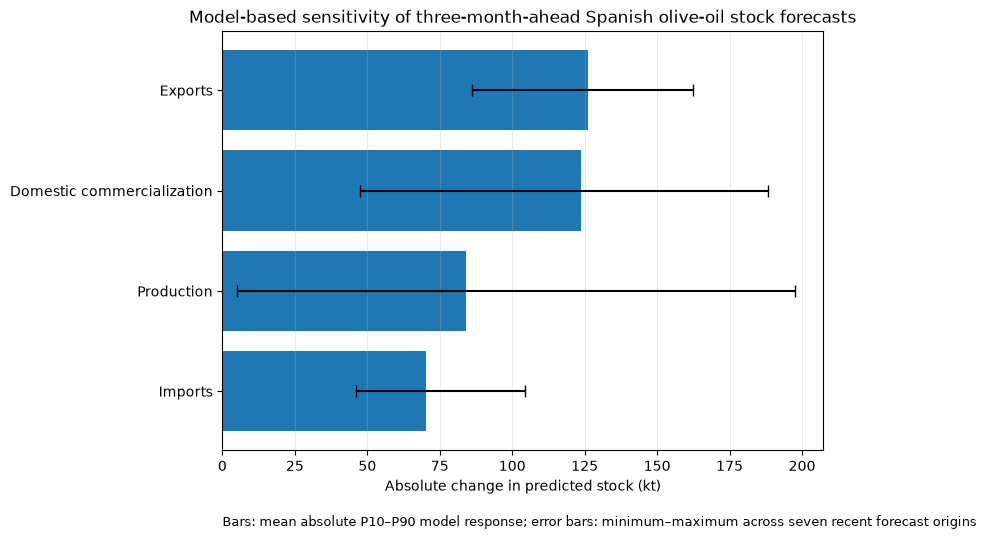

In [67]:
# ============================================================
# CELL 23 — FINAL T+3 SENSITIVITY FIGURE
# Average absolute P10 → P90 sensitivity across recent origins
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# 1. Prepare plotting table
# ------------------------------------------------------------

sensitivity_plot = (
    sensitivity_summary
    .sort_values(
        "mean_absolute_sensitivity_kt",
        ascending=True
    )
    .copy()
)

# Cleaner labels
label_map = {
    "production_kt": "Production",
    "imports_kt": "Imports",
    "exports_kt": "Exports",
    "domestic_market_kt": "Domestic commercialization"
}

sensitivity_plot["label"] = (
    sensitivity_plot["variable"]
    .map(label_map)
)


# ------------------------------------------------------------
# 2. Error-bar distances
# ------------------------------------------------------------

lower_error = (
    sensitivity_plot["mean_absolute_sensitivity_kt"]
    - sensitivity_plot["min_absolute_sensitivity_kt"]
)

upper_error = (
    sensitivity_plot["max_absolute_sensitivity_kt"]
    - sensitivity_plot["mean_absolute_sensitivity_kt"]
)

x_error = np.vstack([
    lower_error,
    upper_error
])


# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.barh(
    sensitivity_plot["label"],
    sensitivity_plot["mean_absolute_sensitivity_kt"],
    xerr=x_error,
    capsize=4
)

ax.set_xlabel(
    "Absolute change in predicted stock (kt)"
)

ax.set_ylabel("")

ax.set_title(
    "Model-based sensitivity of three-month-ahead "
    "Spanish olive-oil stock forecasts"
)

ax.text(
    0,
    -0.18,
    "Bars: mean absolute P10–P90 model response; "
    "error bars: minimum–maximum across seven recent forecast origins",
    transform=ax.transAxes,
    fontsize=9
)

ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()

plt.show()

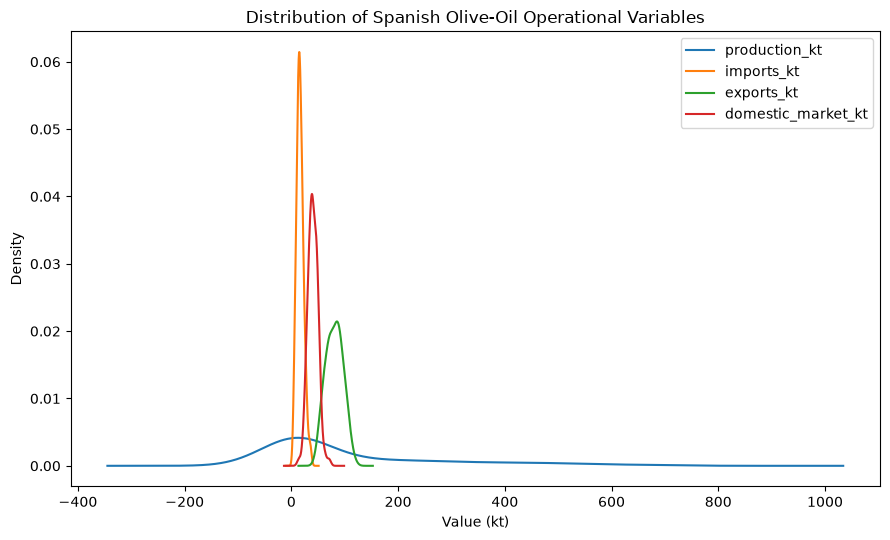

In [68]:
# ============================================================
# CELL 24 — DENSITY OF OPERATIONAL VARIABLES
# ============================================================

import matplotlib.pyplot as plt

density_vars = [
    "production_kt",
    "imports_kt",
    "exports_kt",
    "domestic_market_kt"
]

fig, ax = plt.subplots(figsize=(9, 5.5))

for variable in density_vars:
    stock_intelligence[variable].dropna().plot(
        kind="kde",
        ax=ax,
        label=variable
    )

ax.set_title("Distribution of Spanish Olive-Oil Operational Variables")
ax.set_xlabel("Value (kt)")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.show()

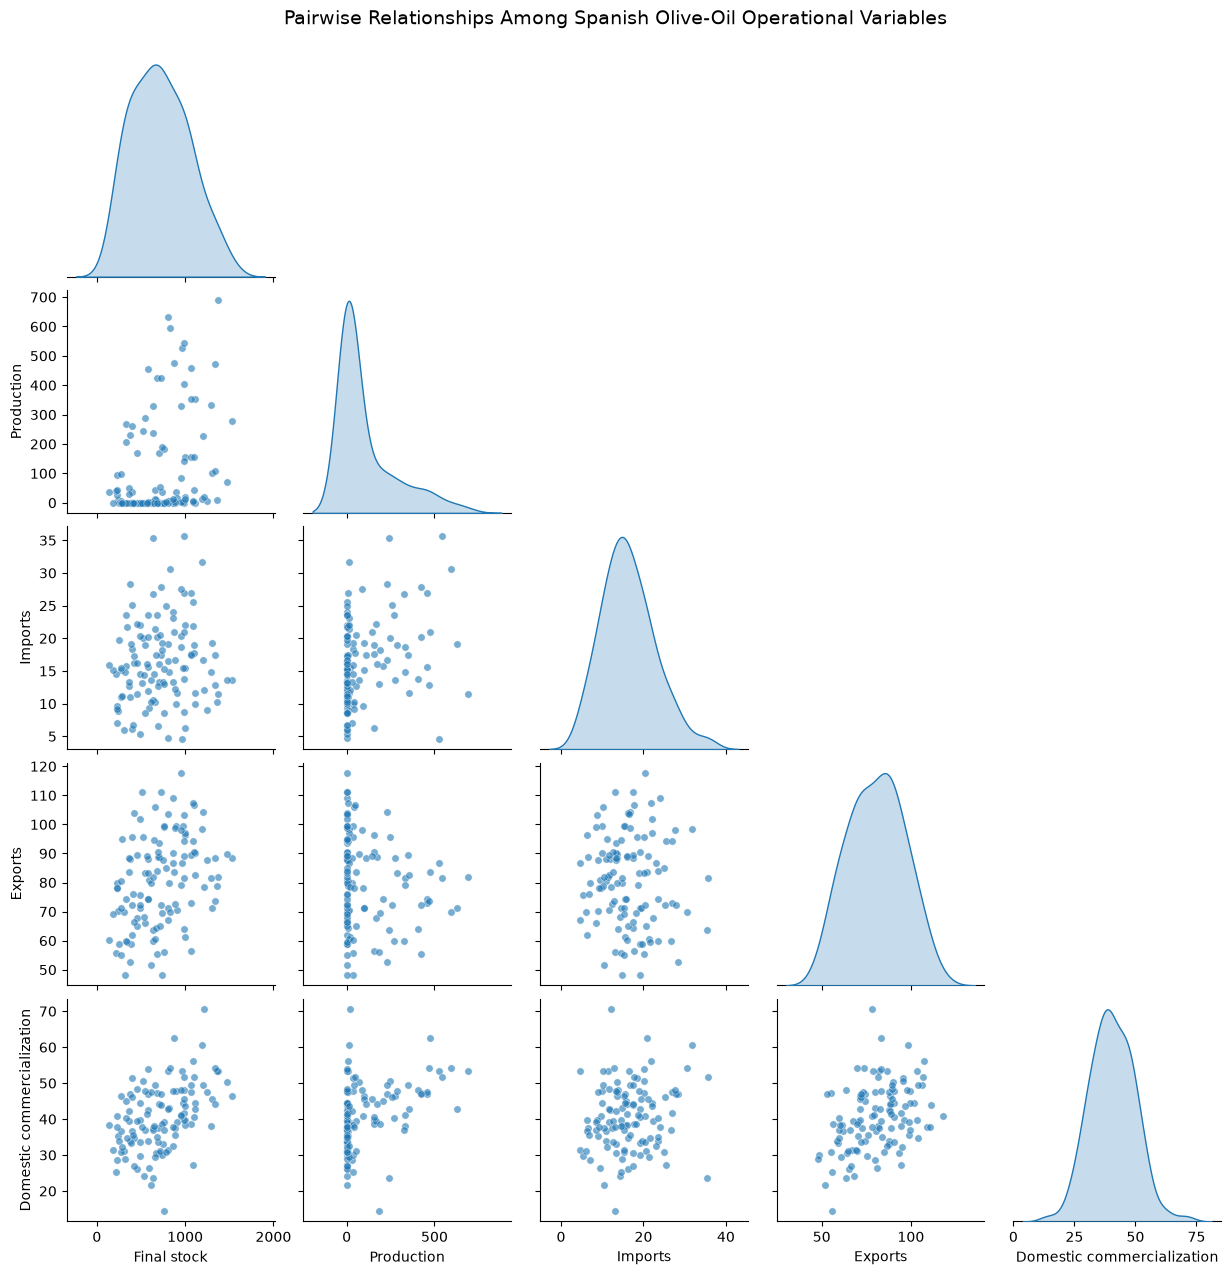

In [69]:
# ============================================================
# CELL 25 — PAIR PLOT OF OPERATIONAL VARIABLES
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt

pair_vars = [
    "final_stock_kt",
    "production_kt",
    "imports_kt",
    "exports_kt",
    "domestic_market_kt"
]

pair_data = (
    stock_intelligence[pair_vars]
    .dropna()
    .copy()
)

# Cleaner names for the figure
pair_data = pair_data.rename(columns={
    "final_stock_kt": "Final stock",
    "production_kt": "Production",
    "imports_kt": "Imports",
    "exports_kt": "Exports",
    "domestic_market_kt": "Domestic commercialization"
})

g = sns.pairplot(
    pair_data,
    diag_kind="kde",
    corner=True,
    plot_kws={
        "alpha": 0.60,
        "s": 28
    },
    diag_kws={
        "fill": True
    }
)

g.fig.suptitle(
    "Pairwise Relationships Among Spanish Olive-Oil Operational Variables",
    y=1.02,
    fontsize=14
)

plt.show()

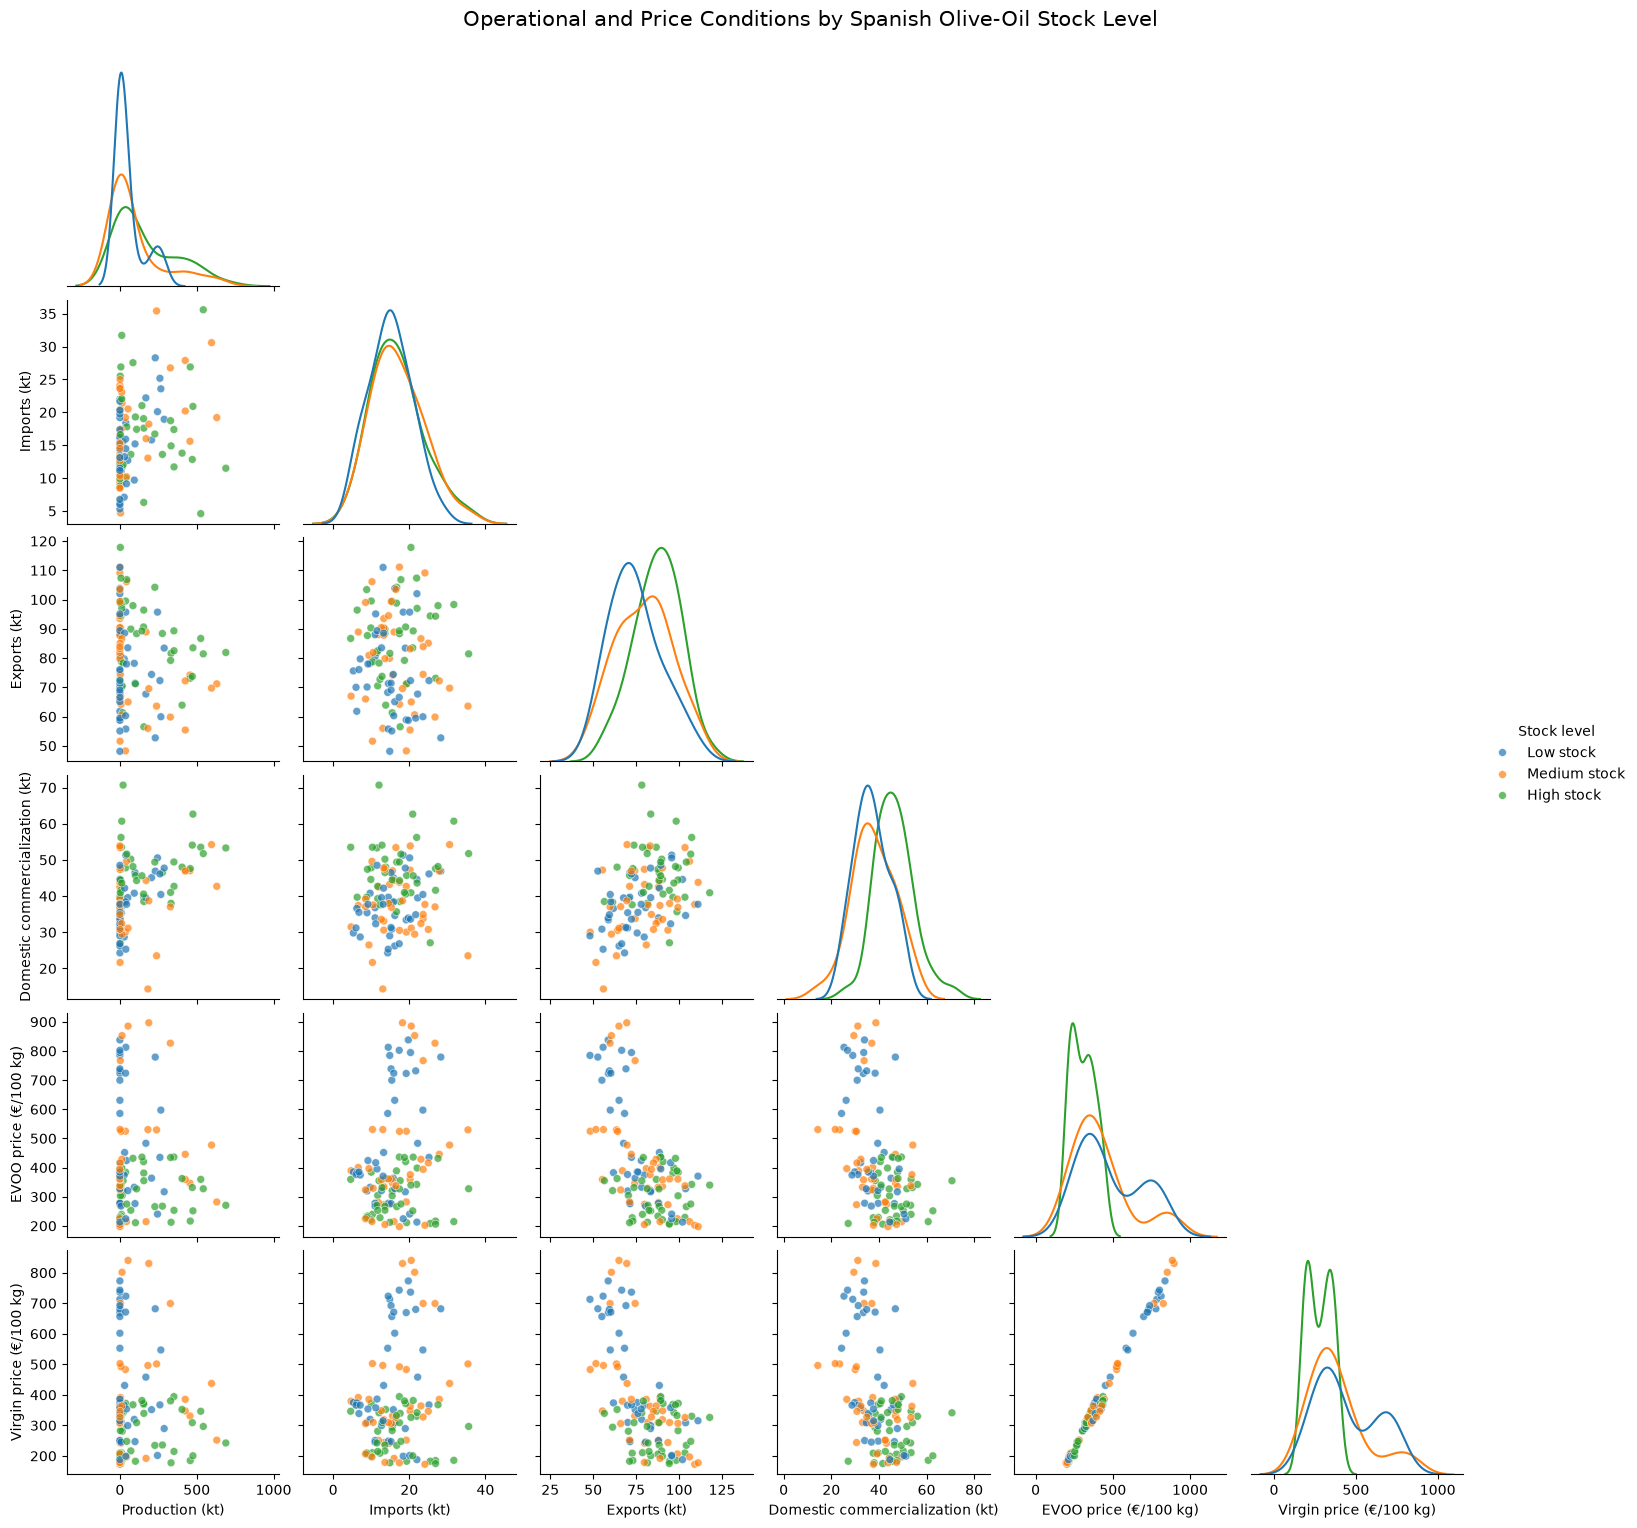

FINAL STOCK TERCILE THRESHOLDS
0.333333    545.86
0.666667    868.28
Name: final_stock_kt, dtype: float64

Observations by stock level:
Stock level
Low stock       39
Medium stock    39
High stock      39
Name: count, dtype: int64


In [70]:
# ============================================================
# CELL 25B — GENERAL EDA PAIR PLOT
# Operational variables + prices
# Colored by Spanish final-stock level
# ============================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Variables for general EDA
# ------------------------------------------------------------

eda_vars = [
    "final_stock_kt",
    "production_kt",
    "imports_kt",
    "exports_kt",
    "domestic_market_kt",
    "evoo_price_t",
    "virgin_price_t"
]


# ------------------------------------------------------------
# 2. Keep complete observations
# ------------------------------------------------------------

eda_pair = (
    stock_intelligence[
        ["date"] + eda_vars
    ]
    .dropna()
    .copy()
)


# ------------------------------------------------------------
# 3. Divide final stock into three equally populated groups
# ------------------------------------------------------------

eda_pair["Stock level"] = pd.qcut(
    eda_pair["final_stock_kt"],
    q=3,
    labels=[
        "Low stock",
        "Medium stock",
        "High stock"
    ]
)


# ------------------------------------------------------------
# 4. Cleaner names for final figure
# ------------------------------------------------------------

eda_pair = eda_pair.rename(columns={

    "final_stock_kt":
        "Final stock (kt)",

    "production_kt":
        "Production (kt)",

    "imports_kt":
        "Imports (kt)",

    "exports_kt":
        "Exports (kt)",

    "domestic_market_kt":
        "Domestic commercialization (kt)",

    "evoo_price_t":
        "EVOO price (€/100 kg)",

    "virgin_price_t":
        "Virgin price (€/100 kg)"
})


# ------------------------------------------------------------
# 5. Pair plot
# ------------------------------------------------------------

plot_vars = [
    "Production (kt)",
    "Imports (kt)",
    "Exports (kt)",
    "Domestic commercialization (kt)",
    "EVOO price (€/100 kg)",
    "Virgin price (€/100 kg)"
]


g = sns.pairplot(
    data=eda_pair,
    vars=plot_vars,
    hue="Stock level",
    diag_kind="kde",
    corner=True,

    plot_kws={
        "alpha": 0.70,
        "s": 32
    },

    diag_kws={
        "fill": False
    }
)


# ------------------------------------------------------------
# 6. Title
# ------------------------------------------------------------

g.fig.suptitle(
    "Operational and Price Conditions by Spanish Olive-Oil Stock Level",
    y=1.02,
    fontsize=15
)

plt.show()


# ------------------------------------------------------------
# 7. Print stock thresholds for documentation
# ------------------------------------------------------------

stock_thresholds = (
    stock_intelligence["final_stock_kt"]
    .quantile([1/3, 2/3])
)

print("FINAL STOCK TERCILE THRESHOLDS")
print(stock_thresholds.round(2))

print("\nObservations by stock level:")
print(
    eda_pair["Stock level"]
    .value_counts(sort=False)
)

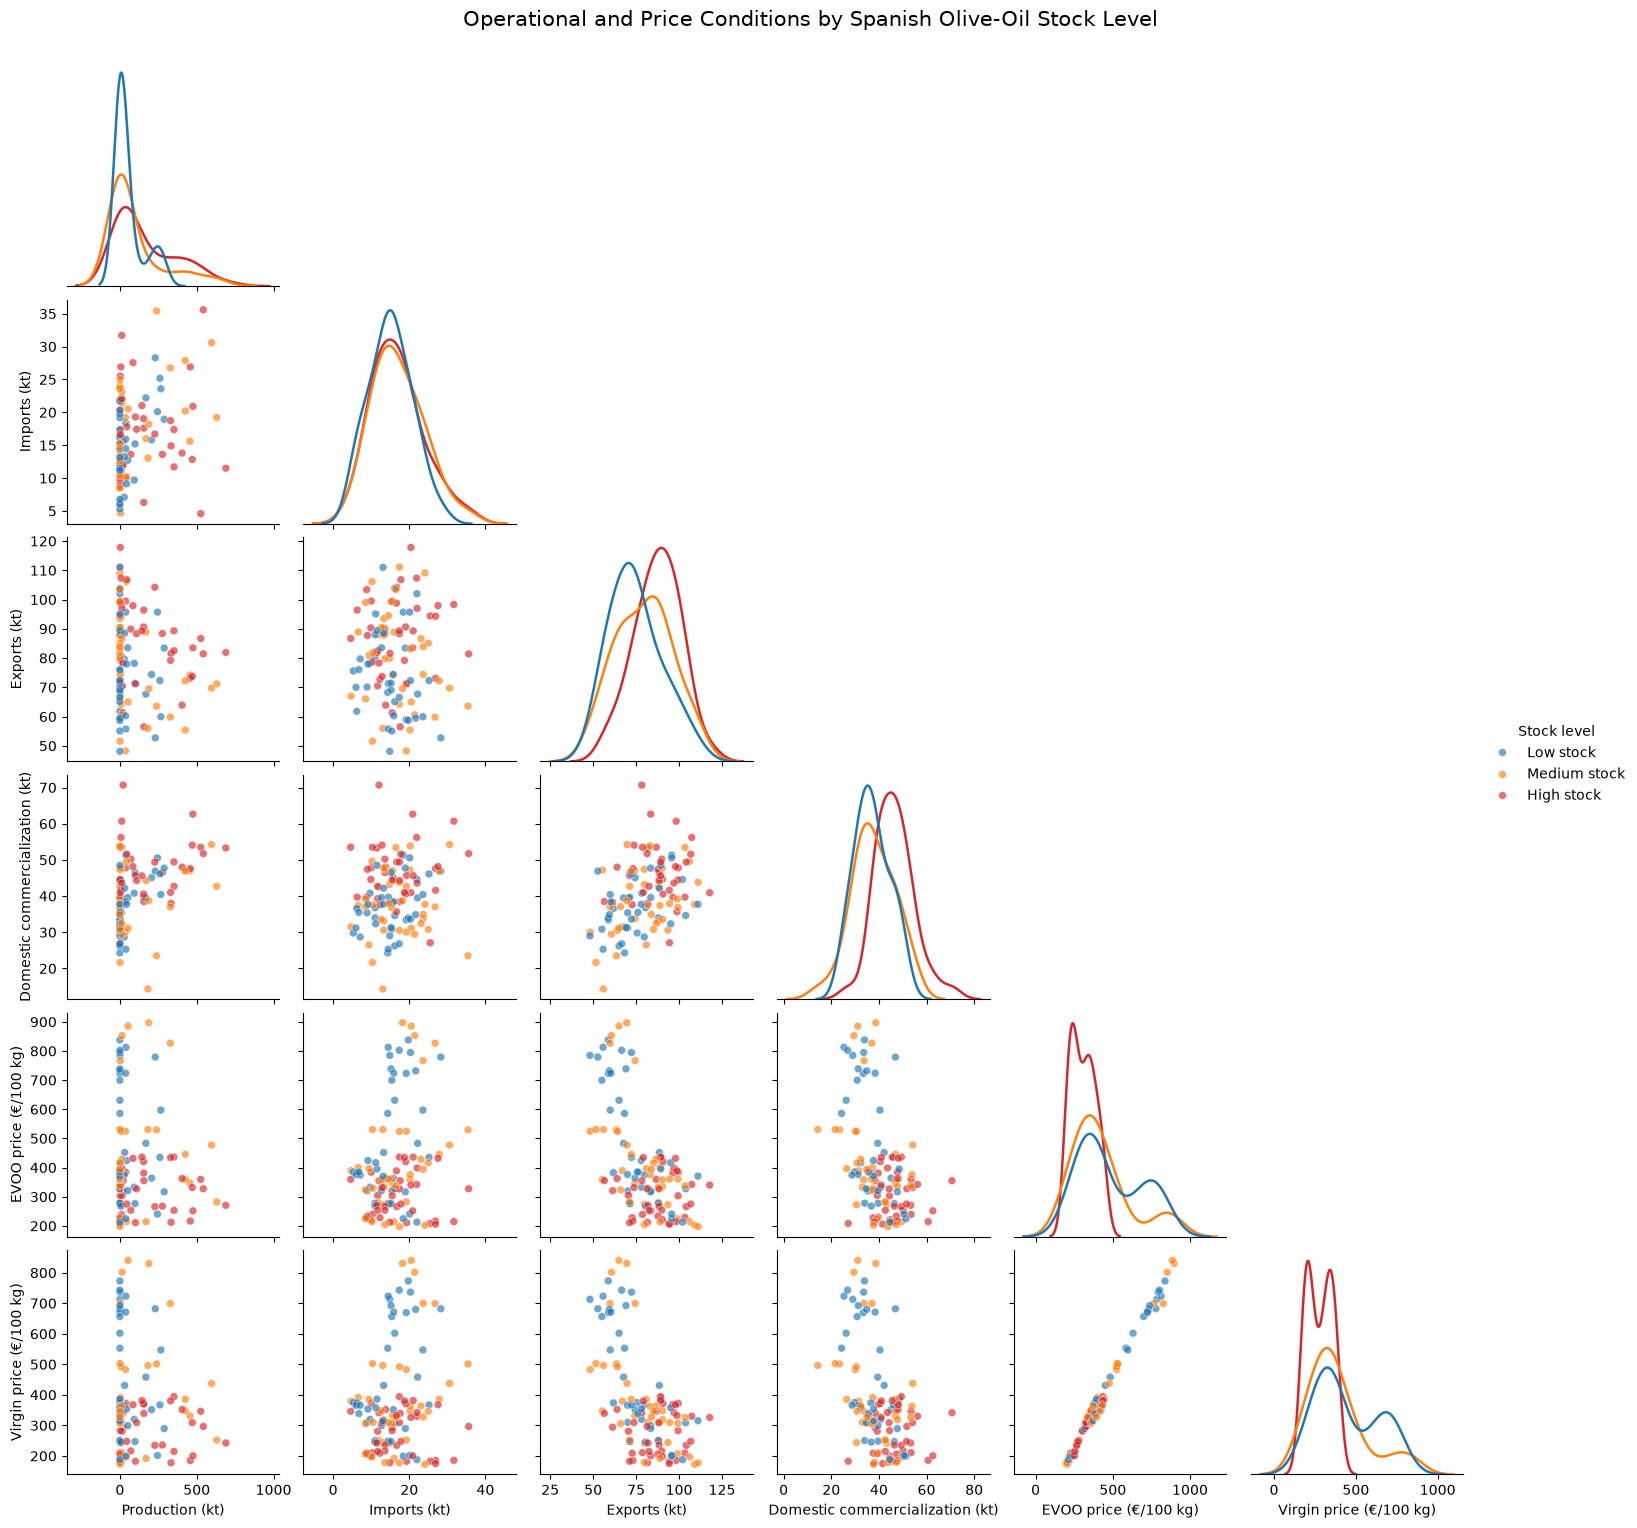

STOCK LEVEL INTERVALS
---------------------
Low stock:    final stock ≤ 544.09 kt
Medium stock: 544.09 < final stock ≤ 868.68 kt
High stock:   final stock > 868.68 kt

Observations:
Stock level
Low stock       39
Medium stock    39
High stock      39
Name: count, dtype: int64


In [71]:
# ============================================================
# CELL 25C — PAIR PLOT COLORED BY STOCK LEVEL
# Low = blue | Medium = orange | High = red
# ============================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

eda_pair = stock_intelligence[
    [
        "date",
        "final_stock_kt",
        "production_kt",
        "imports_kt",
        "exports_kt",
        "domestic_market_kt",
        "evoo_price_t",
        "virgin_price_t"
    ]
].dropna().copy()


# ------------------------------------------------------------
# 2. Calculate exact tercile thresholds
# ------------------------------------------------------------

stock_p33 = eda_pair["final_stock_kt"].quantile(1/3)
stock_p67 = eda_pair["final_stock_kt"].quantile(2/3)

eda_pair["Stock level"] = pd.cut(
    eda_pair["final_stock_kt"],
    bins=[
        -float("inf"),
        stock_p33,
        stock_p67,
        float("inf")
    ],
    labels=[
        "Low stock",
        "Medium stock",
        "High stock"
    ],
    include_lowest=True
)


# ------------------------------------------------------------
# 3. Rename variables
# ------------------------------------------------------------

eda_pair = eda_pair.rename(columns={
    "production_kt": "Production (kt)",
    "imports_kt": "Imports (kt)",
    "exports_kt": "Exports (kt)",
    "domestic_market_kt":
        "Domestic commercialization (kt)",
    "evoo_price_t": "EVOO price (€/100 kg)",
    "virgin_price_t": "Virgin price (€/100 kg)"
})


plot_vars = [
    "Production (kt)",
    "Imports (kt)",
    "Exports (kt)",
    "Domestic commercialization (kt)",
    "EVOO price (€/100 kg)",
    "Virgin price (€/100 kg)"
]


# ------------------------------------------------------------
# 4. Fixed color palette
# ------------------------------------------------------------

stock_palette = {
    "Low stock": "tab:blue",
    "Medium stock": "tab:orange",
    "High stock": "tab:red"
}


# ------------------------------------------------------------
# 5. Pair plot
# ------------------------------------------------------------

g = sns.pairplot(
    data=eda_pair,
    vars=plot_vars,
    hue="Stock level",
    hue_order=[
        "Low stock",
        "Medium stock",
        "High stock"
    ],
    palette=stock_palette,
    corner=True,
    diag_kind="kde",
    plot_kws={
        "alpha": 0.65,
        "s": 32
    },
    diag_kws={
        "fill": False,
        "linewidth": 1.8
    }
)

g.fig.suptitle(
    "Operational and Price Conditions by Spanish Olive-Oil Stock Level",
    y=1.02,
    fontsize=15
)

plt.show()


# ------------------------------------------------------------
# 6. Print exact intervals
# ------------------------------------------------------------

print("STOCK LEVEL INTERVALS")
print("---------------------")

print(
    f"Low stock:    final stock ≤ {stock_p33:.2f} kt"
)

print(
    f"Medium stock: {stock_p33:.2f} < final stock "
    f"≤ {stock_p67:.2f} kt"
)

print(
    f"High stock:   final stock > {stock_p67:.2f} kt"
)

print("\nObservations:")
print(
    eda_pair["Stock level"]
    .value_counts(sort=False)
)

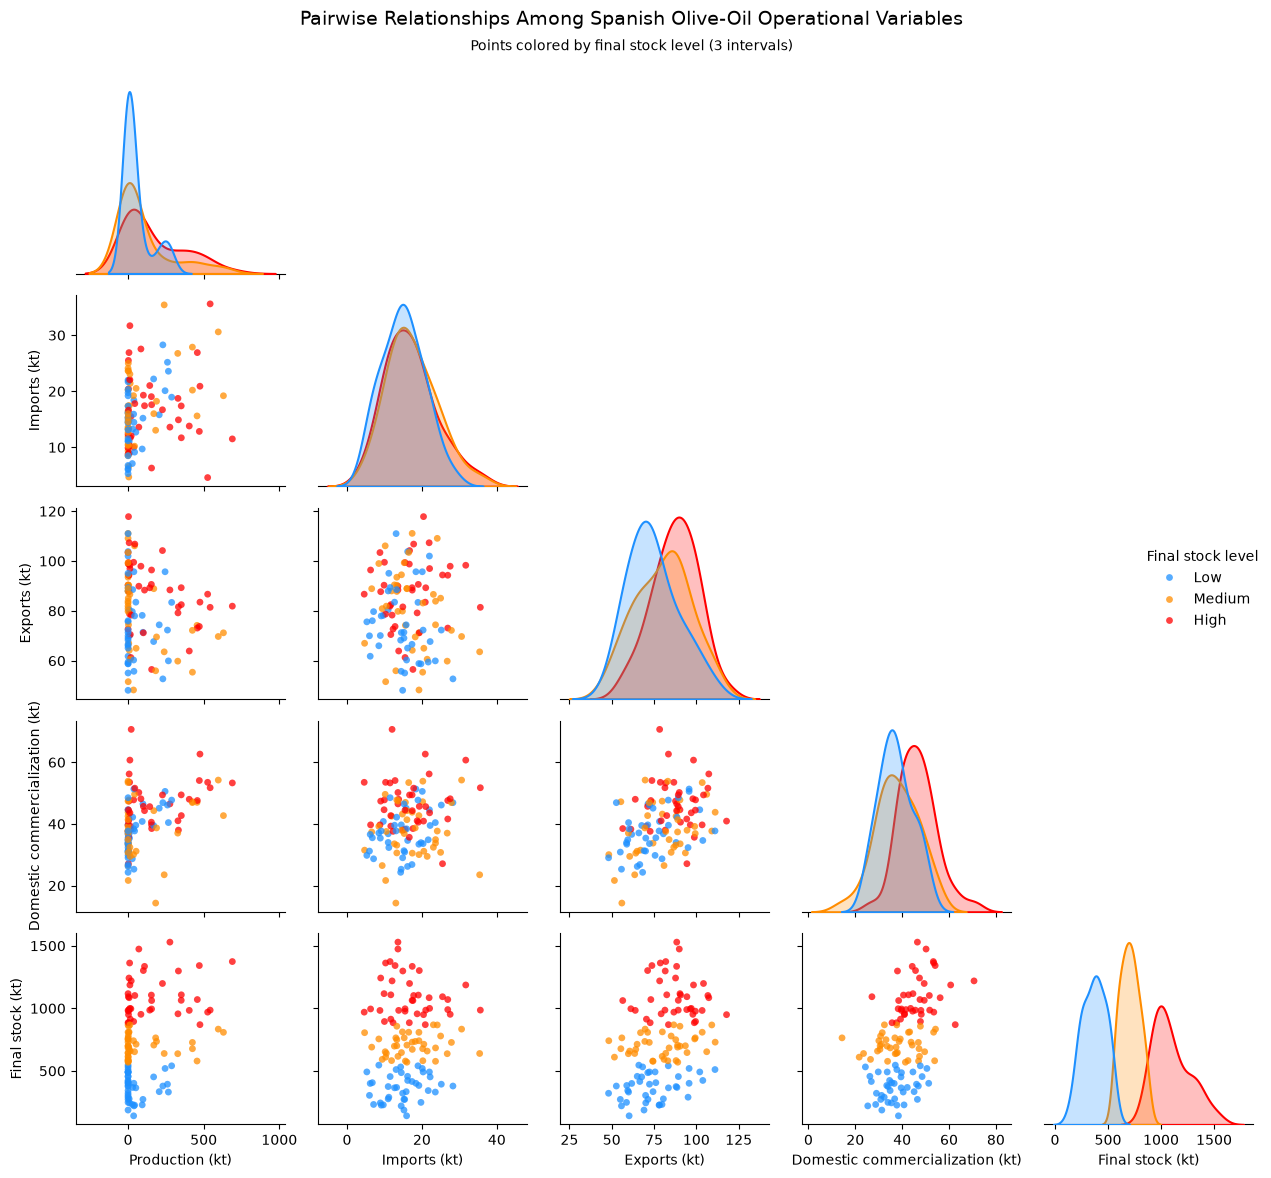

FINAL STOCK LEVEL INTERVALS
---------------------------
Low:    ≤ 545.86 kt
Medium: 545.86 to 868.28 kt
High:   > 868.28 kt


In [72]:
# ============================================================
# CELL 25E — COMPACT PAIRPLOT
# Operational variables + Final stock
# Colored by stock level
# ============================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

pair_stock = stock_intelligence[
    [
        "final_stock_kt",
        "production_kt",
        "imports_kt",
        "exports_kt",
        "domestic_market_kt"
    ]
].dropna().copy()


# ------------------------------------------------------------
# 2. Stock tercile thresholds
# ------------------------------------------------------------

p33 = pair_stock["final_stock_kt"].quantile(1/3)
p67 = pair_stock["final_stock_kt"].quantile(2/3)

pair_stock["Final stock level"] = pd.cut(
    pair_stock["final_stock_kt"],
    bins=[
        -float("inf"),
        p33,
        p67,
        float("inf")
    ],
    labels=[
        "Low",
        "Medium",
        "High"
    ],
    include_lowest=True
)


# ------------------------------------------------------------
# 3. Rename variables
# ------------------------------------------------------------

pair_stock = pair_stock.rename(columns={
    "production_kt": "Production (kt)",
    "imports_kt": "Imports (kt)",
    "exports_kt": "Exports (kt)",
    "domestic_market_kt": "Domestic commercialization (kt)",
    "final_stock_kt": "Final stock (kt)"
})


# ------------------------------------------------------------
# 4. Fixed palette
# ------------------------------------------------------------

palette_stock = {
    "Low": "dodgerblue",
    "Medium": "darkorange",
    "High": "red"
}


# ------------------------------------------------------------
# 5. Pairplot
# ------------------------------------------------------------

g = sns.pairplot(
    pair_stock,
    vars=[
        "Production (kt)",
        "Imports (kt)",
        "Exports (kt)",
        "Domestic commercialization (kt)",
        "Final stock (kt)"
    ],
    hue="Final stock level",
    hue_order=[
        "Low",
        "Medium",
        "High"
    ],
    palette=palette_stock,
    corner=True,
    diag_kind="kde",
    height=2.3,
    aspect=1,

    plot_kws={
        "s": 24,
        "alpha": 0.75,
        "edgecolor": "none"
    },

    diag_kws={
        "fill": True,
        "alpha": 0.25,
        "linewidth": 1.5
    }
)


# ------------------------------------------------------------
# 6. Title
# ------------------------------------------------------------

g.fig.suptitle(
    "Pairwise Relationships Among Spanish Olive-Oil Operational Variables",
    y=1.02,
    fontsize=14
)

g.fig.text(
    0.5,
    0.985,
    "Points colored by final stock level (3 intervals)",
    ha="center",
    fontsize=10
)


# ------------------------------------------------------------
# 7. Improve legend
# ------------------------------------------------------------

if g._legend is not None:
    g._legend.set_title("Final stock level")


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Print exact intervals
# ------------------------------------------------------------

print("FINAL STOCK LEVEL INTERVALS")
print("---------------------------")
print(f"Low:    ≤ {p33:.2f} kt")
print(f"Medium: {p33:.2f} to {p67:.2f} kt")
print(f"High:   > {p67:.2f} kt")

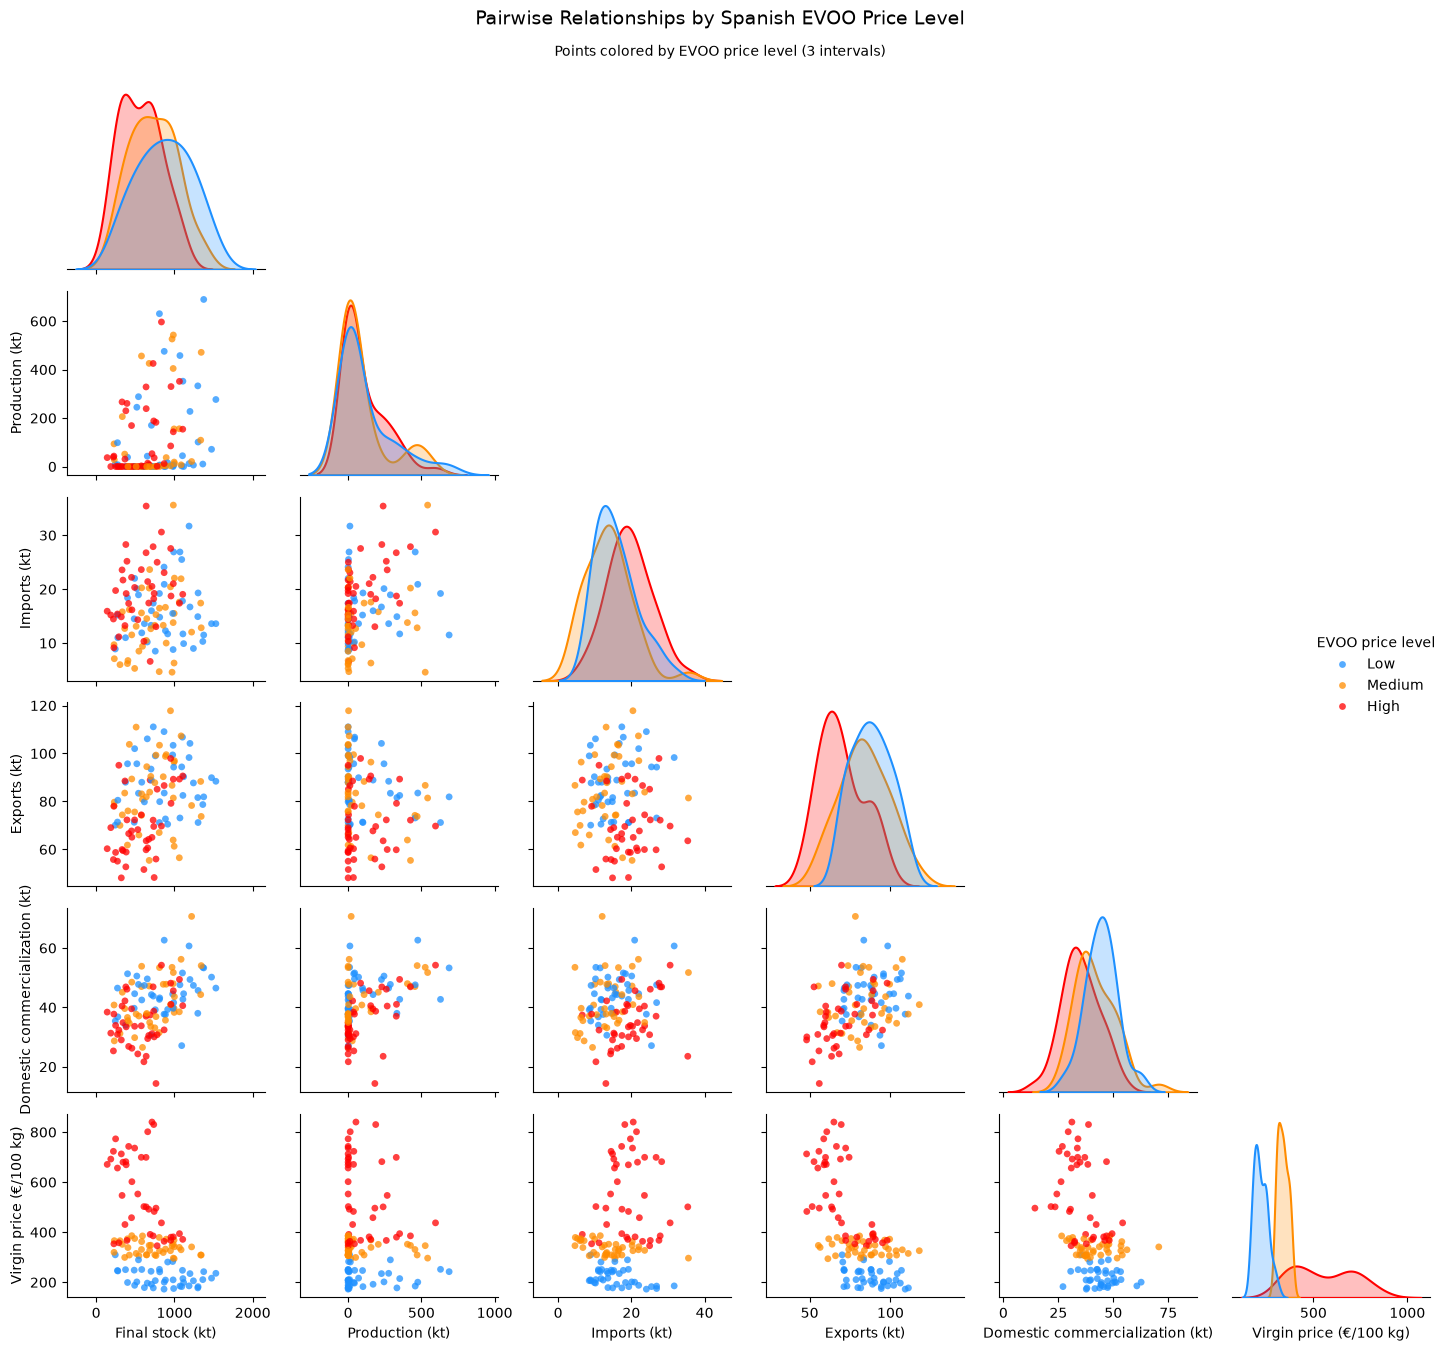

EVOO PRICE LEVEL INTERVALS
--------------------------
Low:    ≤ 320.45 €/100 kg
Medium: 320.45 to 399.12 €/100 kg
High:   > 399.12 €/100 kg


In [73]:
# ============================================================
# CELL 25F — COMPACT PAIRPLOT BY EVOO PRICE LEVEL
# Low = blue | Medium = orange | High = red
# ============================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

pair_price = stock_intelligence[
    [
        "final_stock_kt",
        "production_kt",
        "imports_kt",
        "exports_kt",
        "domestic_market_kt",
        "evoo_price_t",
        "virgin_price_t"
    ]
].dropna().copy()


# ------------------------------------------------------------
# 2. EVOO price tercile thresholds
# ------------------------------------------------------------

price_p33 = pair_price["evoo_price_t"].quantile(1/3)
price_p67 = pair_price["evoo_price_t"].quantile(2/3)

pair_price["EVOO price level"] = pd.cut(
    pair_price["evoo_price_t"],
    bins=[
        -float("inf"),
        price_p33,
        price_p67,
        float("inf")
    ],
    labels=[
        "Low",
        "Medium",
        "High"
    ],
    include_lowest=True
)


# ------------------------------------------------------------
# 3. Rename variables
# ------------------------------------------------------------

pair_price = pair_price.rename(columns={
    "final_stock_kt": "Final stock (kt)",
    "production_kt": "Production (kt)",
    "imports_kt": "Imports (kt)",
    "exports_kt": "Exports (kt)",
    "domestic_market_kt": "Domestic commercialization (kt)",
    "virgin_price_t": "Virgin price (€/100 kg)"
})


# ------------------------------------------------------------
# 4. Fixed palette
# ------------------------------------------------------------

palette_price = {
    "Low": "dodgerblue",
    "Medium": "darkorange",
    "High": "red"
}


# ------------------------------------------------------------
# 5. Pairplot
# ------------------------------------------------------------

g = sns.pairplot(
    pair_price,
    vars=[
        "Final stock (kt)",
        "Production (kt)",
        "Imports (kt)",
        "Exports (kt)",
        "Domestic commercialization (kt)",
        "Virgin price (€/100 kg)"
    ],
    hue="EVOO price level",
    hue_order=[
        "Low",
        "Medium",
        "High"
    ],
    palette=palette_price,
    corner=True,
    diag_kind="kde",
    height=2.2,
    aspect=1,

    plot_kws={
        "s": 24,
        "alpha": 0.75,
        "edgecolor": "none"
    },

    diag_kws={
        "fill": True,
        "alpha": 0.25,
        "linewidth": 1.5
    }
)


# ------------------------------------------------------------
# 6. Title
# ------------------------------------------------------------

g.fig.suptitle(
    "Pairwise Relationships by Spanish EVOO Price Level",
    y=1.02,
    fontsize=14
)

g.fig.text(
    0.5,
    0.985,
    "Points colored by EVOO price level (3 intervals)",
    ha="center",
    fontsize=10
)


# ------------------------------------------------------------
# 7. Legend
# ------------------------------------------------------------

if g._legend is not None:
    g._legend.set_title("EVOO price level")


plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Print exact price intervals
# ------------------------------------------------------------

print("EVOO PRICE LEVEL INTERVALS")
print("--------------------------")

print(f"Low:    ≤ {price_p33:.2f} €/100 kg")
print(
    f"Medium: {price_p33:.2f} to "
    f"{price_p67:.2f} €/100 kg"
)
print(f"High:   > {price_p67:.2f} €/100 kg")